# Diffusion Models for the 1D Burgers' Equation

**Authors:** Jona Kao, Niclas Leinen

This notebook implements a **conditional Denoising Diffusion Probabilistic Model (DDPM)** that
learns the distribution of solutions to the 1-D viscous Burgers' equation:

$$\partial_t u + u \, \partial_x u = \nu \, \partial_{xx} u$$

Given random initial conditions $u(x,0)$, the model generates the full space–time evolution
$u(x,t)$.  Ground-truth solutions are computed **analytically** via the Cole–Hopf transformation.

**Evaluation metrics:**
- Relative $L^2$ error against analytic solutions
- Shock position and width accuracy
- Kinetic energy decay comparison

In [ ]:
import copy
import math
import matplotlib.pyplot as plt
import numpy as np
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
import warnings

from matplotlib import cm
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from scipy.stats import spearmanr
from scipy.stats import wasserstein_distance
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm

# Device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

# Reproducibility
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

# Physical parameters
NU       = 0.05          # kinematic viscosity
L        = 2 * np.pi     # domain length [0, L), periodic
NX       = 128           # spatial grid points
NT       = 32            # temporal grid points (incl. t = 0)
T_FINAL  = 1.0           # final simulation time

# Initial-condition generation
N_MODES      = 10        # Fourier modes
IC_AMPLITUDE = 0.7       # amplitude scale (reduced to limit extreme tails)

# Dataset sizes
N_TRAIN = 4000
N_TEST  = 500

# DDPM hyper-parameters
DIFFUSION_STEPS = 1000
BETA_MIN = 1e-4
BETA_MAX = 0.02

# Training hyper-parameters
BATCH_SIZE    = 64
LEARNING_RATE = 1e-4
N_EPOCHS      = 300
GRAD_CLIP     = 1.0

Using device: cuda


## 1. Data Generation - Cole–Hopf Analytic Solver

The Cole–Hopf transformation $u = -2\nu\,\frac{\partial_x \phi}{\phi}$ maps Burgers' equation
to the linear **heat equation** $\partial_t \phi = \nu\,\partial_{xx}\phi$, solvable exactly in
Fourier space.

**Pipeline per sample:**
1. Draw a smooth random initial condition $u(x,0)$ from a truncated Fourier series.
2. Compute $\phi(x,0) = \exp\!\bigl(-\tfrac{1}{2\nu}\int_0^x u(s,0)\,ds\bigr)$.
3. Evolve $\hat\phi_k(t) = \hat\phi_k(0)\,e^{-\nu k^2 t}$ in Fourier space.
4. Recover $u(x,t) = -2\nu\,\tfrac{\partial_x\phi}{\phi}$.

In [ ]:
def sample_initial_condition(N_x, L, n_modes=10, amplitude=1.0, rng=None):
    """Sample a smooth, zero-mean, periodic IC via random Fourier series."""
    if rng is None:
        rng = np.random.default_rng()
        
    x = np.linspace(0, L, N_x, endpoint=False)
    u0 = np.zeros(N_x)
    
    for k in range(1, n_modes + 1):
        ak = rng.normal(0, amplitude / k)
        bk = rng.normal(0, amplitude / k)
        u0 += ak * np.sin(2 * np.pi * k * x / L) + bk * np.cos(2 * np.pi * k * x / L)
    
    return u0, x

In [ ]:
def solve_burgers_cole_hopf(u0, nu, L, T, N_t):
    """
    Solve 1-D viscous Burgers' equation analytically via Cole-Hopf.
    """
    N_x = len(u0)
    dx  = L / N_x
    x   = np.linspace(0, L, N_x, endpoint=False)
    t   = np.linspace(0, T, N_t)

    u0 = np.asarray(u0, dtype=np.float64)

    # Cumulative integral  Phi(x) = int_0^x u(s,0) ds  (trapezoidal)
    Phi = np.zeros(N_x, dtype=np.float64)
    
    for i in range(1, N_x):
        Phi[i] = Phi[i - 1] + 0.5 * (u0[i - 1] + u0[i]) * dx

    # phi(x, 0) = exp( -Phi / (2 nu) ),  shift for numerical stability
    exponent = -Phi / (2.0 * nu)
    exponent -= exponent.mean()
    phi0 = np.exp(exponent)

    # Wavenumbers
    k_freq   = np.fft.fftfreq(N_x, d=dx) * 2.0 * np.pi
    phi0_hat = np.fft.fft(phi0)

    u    = np.zeros((N_t, N_x), dtype=np.float64)
    u[0] = u0

    for n in range(1, N_t):
        decay    = np.exp(-nu * k_freq**2 * t[n])
        phi_hat  = phi0_hat * decay
        phi      = np.fft.ifft(phi_hat).real
        dphi_hat = 1j * k_freq * phi_hat
        dphi     = np.fft.ifft(dphi_hat).real

        # Stable division with explicit floor to avoid divide-by-zero warnings
        safe_phi = np.where(np.abs(phi) > 1e-15, phi, np.sign(phi) * 1e-15)
        
        with np.errstate(divide='ignore', invalid='ignore'):
            u[n] = -2.0 * nu * dphi / safe_phi

    return u, x, t


# Sanity check
u0_test, x_test = sample_initial_condition(NX, L, N_MODES, IC_AMPLITUDE,
                                           rng=np.random.default_rng(0))
u_test, _, t_test = solve_burgers_cole_hopf(u0_test, NU, L, T_FINAL, NT)
print(f"Solution shape : {u_test.shape}  (N_t x N_x)")
print(f"Max |u|        : {np.abs(u_test).max():.4f}")
print(f"Energy at t=0  : {0.5*np.mean(u_test[0]**2):.4f}")
print(f"Energy at t=T  : {0.5*np.mean(u_test[-1]**2):.4f}")

Solution shape : (32, 128)  (N_t x N_x)
Max |u|        : 0.7941
Energy at t=0  : 0.0739
Energy at t=T  : 0.0201


In [ ]:
MAX_ABS_U = 10.0   # reject samples where |u| exceeds this (numerical artefact)

def generate_dataset(N_samples, N_x, L, nu, T, N_t, n_modes, amplitude, seed=0):
    """Generate N_samples Burgers solutions with random ICs.
    Samples that produce extreme values (Cole-Hopf instability) are re-drawn."""
    rng  = np.random.default_rng(seed)
    data = np.zeros((N_samples, N_t, N_x), dtype=np.float32)
    rejected = 0
    
    for i in tqdm(range(N_samples), desc="Generating"):
        while True:
            u0, _ = sample_initial_condition(N_x, L, n_modes, amplitude, rng=rng)
            sol, _, _ = solve_burgers_cole_hopf(u0, nu, L, T, N_t)
            
            if np.all(np.isfinite(sol)) and np.abs(sol).max() < MAX_ABS_U:
                break
            
            rejected += 1
        
        data[i] = sol.astype(np.float32)
    
    if rejected > 0:
        print(f"  (rejected {rejected} unstable samples)")
    
    return data

In [ ]:
print("Generating training set ...")
train_data = generate_dataset(N_TRAIN, NX, L, NU, T_FINAL, NT,
                              N_MODES, IC_AMPLITUDE, seed=42)
print("Generating test set ...")
test_data  = generate_dataset(N_TEST,  NX, L, NU, T_FINAL, NT,
                              N_MODES, IC_AMPLITUDE, seed=12345)

print(f"Training data : {train_data.shape}")
print(f"Test data     : {test_data.shape}")
print(f"  max |u| in train: {np.abs(train_data).max():.4f}")
print(f"  max |u| in test : {np.abs(test_data).max():.4f}")

Generating training set ...


Generating: 100%|██████████| 4000/4000 [00:05<00:00, 714.21it/s]


  (rejected 471 unstable samples)
Generating test set ...


Generating: 100%|██████████| 500/500 [00:00<00:00, 710.14it/s]


  (rejected 67 unstable samples)
Training data : (4000, 32, 128)
Test data     : (500, 32, 128)
  max |u| in train: 9.9939
  max |u| in test : 9.6767


## 2. Data Normalisation & Visualisation

DDPM operates best when the data is approximately standard-normal. We compute global mean and
standard deviation from the **training set** and apply them to both splits.

In [ ]:
# Global normalisation (computed on training set)
data_mean = train_data.mean()
data_std  = train_data.std()

train_data_norm = (train_data - data_mean) / data_std
test_data_norm  = (test_data  - data_mean) / data_std

print(f"Normalisation stats  -  mean: {data_mean:.6f},  std: {data_std:.6f}")
print(f"After normalisation  -  train range: [{train_data_norm.min():.2f}, {train_data_norm.max():.2f}]")
print(f"                        test  range: [{test_data_norm.min():.2f}, {test_data_norm.max():.2f}]")

Normalisation stats  —  mean: 0.000002,  std: 0.696502
After normalisation  —  train range: [-13.25, 14.35]
                        test  range: [-13.89, 10.32]


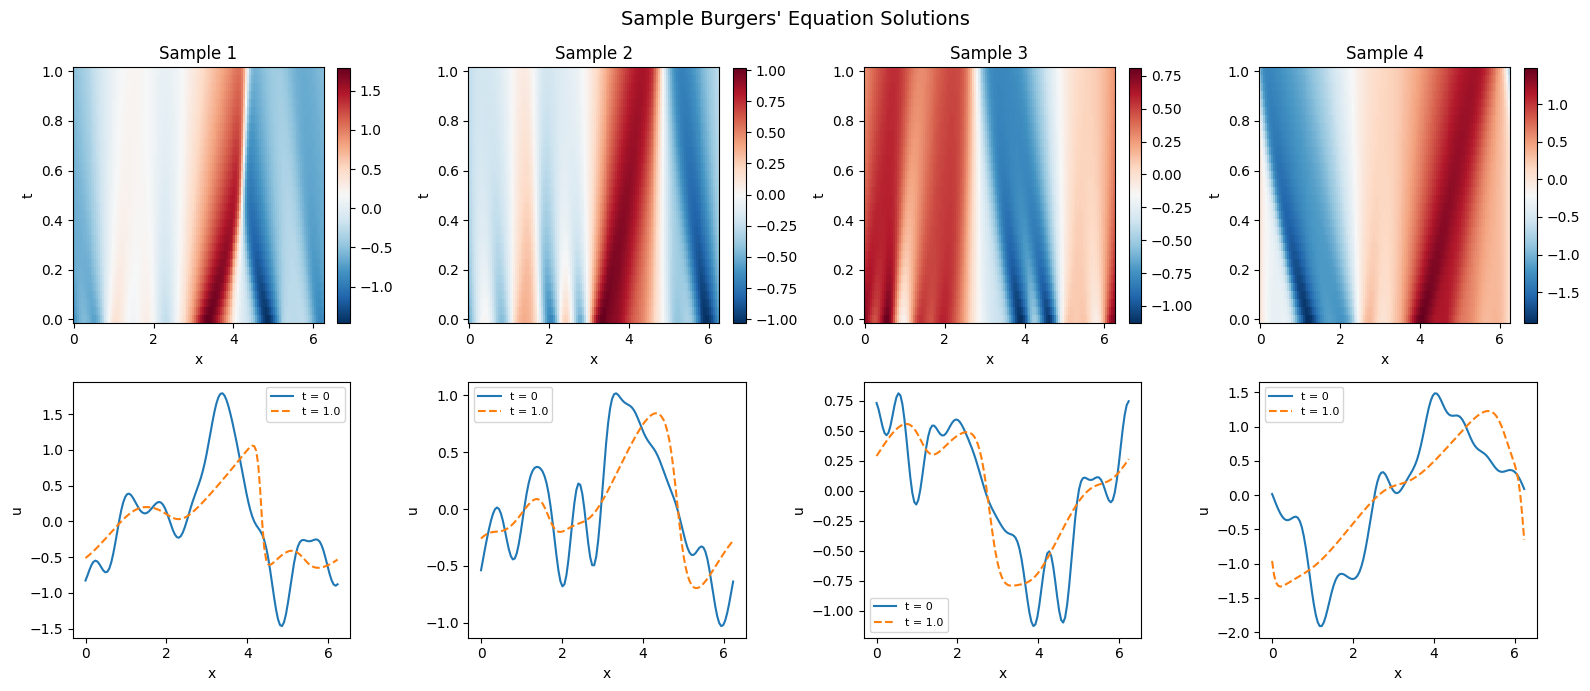

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
x_grid = np.linspace(0, L, NX, endpoint=False)
t_grid = np.linspace(0, T_FINAL, NT)

for i in range(4):
    # Space-time heatmap
    ax = axes[0, i]
    im = ax.pcolormesh(x_grid, t_grid, train_data[i],
                       cmap='RdBu_r', shading='auto')
    ax.set_xlabel('x'); ax.set_ylabel('t')
    ax.set_title(f'Sample {i+1}')
    plt.colorbar(im, ax=ax, fraction=0.046)

    # Initial & final profiles
    ax2 = axes[1, i]
    ax2.plot(x_grid, train_data[i, 0],  label='t = 0')
    ax2.plot(x_grid, train_data[i, -1], label=f't = {T_FINAL}', ls='--')
    ax2.set_xlabel('x'); ax2.set_ylabel('u')
    ax2.legend(fontsize=8)

fig.suptitle("Sample Burgers' Equation Solutions", fontsize=14)
plt.tight_layout()
plt.show()

## 3. Denoising Diffusion Probabilistic Model (DDPM)

We employ a **1-D U-Net** where the $N_t$ time slices serve as **channels** and the $N_x$ spatial
points form the **sequence dimension**.

**Conditioning:** The initial condition $u(x,0)$ is concatenated as an extra channel, yielding
input shape $(N_t+1,\; N_x)$.  The model predicts the noise $\varepsilon$ of shape
$(N_t,\; N_x)$.

**Noise schedule:** Linear $\beta$-schedule from $\beta_1 = 10^{-4}$ to $\beta_T = 0.02$ with
$T = 1000$ diffusion steps.

In [ ]:
# DDPM noise schedule
betas  = torch.linspace(BETA_MIN, BETA_MAX, DIFFUSION_STEPS, device=device)
alphas = 1.0 - betas
alpha_bar = torch.cumprod(alphas, dim=0)
alpha_bar_prev = F.pad(alpha_bar[:-1], (1, 0), value=1.0)

sqrt_alpha_bar         = torch.sqrt(alpha_bar)
sqrt_one_minus_alpha_bar = torch.sqrt(1.0 - alpha_bar)
posterior_variance     = betas * (1.0 - alpha_bar_prev) / (1.0 - alpha_bar)


def q_sample(x0, t, noise=None):
    """Forward diffusion: sample x_t given x_0."""
    if noise is None:
        noise = torch.randn_like(x0)
    
    sa = sqrt_alpha_bar[t][:, None, None]
    sm = sqrt_one_minus_alpha_bar[t][:, None, None]
    
    return sa * x0 + sm * noise, noise

print("Noise schedule ready.")
print(f"  alpha_bar[0]   = {alpha_bar[0]:.6f}")
print(f"  alpha_bar[-1]  = {alpha_bar[-1]:.6f}")

Noise schedule ready.
  alpha_bar[0]   = 0.999900
  alpha_bar[-1]  = 0.000040


In [ ]:
class SinusoidalPosEmb(nn.Module):
    """Sinusoidal time-step embeddings (Vaswani et al., 2017)."""
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        half = self.dim // 2
        
        emb  = math.log(10_000) / (half - 1)
        emb  = torch.exp(torch.arange(half, device=t.device) * -emb)
        emb  = t[:, None].float() * emb[None, :]
        
        return torch.cat([emb.sin(), emb.cos()], dim=-1)

In [ ]:
class SelfAttention1D(nn.Module):
    """
    Multi-head self-attention for 1-D feature maps.
    Placed in the U-Net bottleneck to capture long-range spatial dependencies
    (e.g. correlations between shock fronts and rarefaction regions).
    """
    def __init__(self, channels, n_heads=4):
        super().__init__()
        
        self.n_heads = n_heads
        self.norm = nn.GroupNorm(8, channels)
        self.qkv  = nn.Conv1d(channels, channels * 3, 1)
        self.proj  = nn.Conv1d(channels, channels, 1)
        self.scale = (channels // n_heads) ** -0.5

    def forward(self, x):
        B, C, W = x.shape
        h = self.norm(x)
        qkv = self.qkv(h).reshape(B, 3, self.n_heads, C // self.n_heads, W)
        q, k, v = qkv[:, 0], qkv[:, 1], qkv[:, 2]   # each (B, heads, d, W)
        
        # Attention over spatial dimension
        q = q.permute(0, 1, 3, 2)  # (B, heads, W, d)
        k = k.permute(0, 1, 3, 2)
        v = v.permute(0, 1, 3, 2)
        
        attn = torch.matmul(q, k.transpose(-2, -1)) * self.scale
        attn = attn.softmax(dim=-1)
        
        out = torch.matmul(attn, v)  # (B, heads, W, d)
        out = out.permute(0, 1, 3, 2).reshape(B, C, W)
        
        return x + self.proj(out)

In [ ]:
class ResBlock1D(nn.Module):
    """Residual block with GroupNorm, SiLU, and diffusion-time injection."""
    def __init__(self, in_ch, out_ch, t_dim, groups=8):
        super().__init__()
        
        self.norm1  = nn.GroupNorm(groups, in_ch)
        self.conv1  = nn.Conv1d(in_ch, out_ch, 3, padding=1)
        self.t_proj = nn.Linear(t_dim, out_ch)
        self.norm2  = nn.GroupNorm(groups, out_ch)
        self.conv2  = nn.Conv1d(out_ch, out_ch, 3, padding=1)
        self.skip   = nn.Conv1d(in_ch, out_ch, 1) if in_ch != out_ch else nn.Identity()
        self.act    = nn.SiLU()

    def forward(self, x, t_emb):
        h = self.act(self.norm1(x))
        h = self.conv1(h)
        h = h + self.t_proj(t_emb)[:, :, None]
        h = self.act(self.norm2(h))
        h = self.conv2(h)
        
        return h + self.skip(x)

In [ ]:
class UNet1D(nn.Module):
    """
    1-D U-Net for DDPM with self-attention in the bottleneck.

    Parameters
    ----------
    in_ch   : input channels  (N_t + 1 with condition, or N_t for unconditional)
    out_ch  : output channels (N_t)
    base_ch : base channel width
    ch_mult : channel multipliers per resolution level
    t_dim   : diffusion-time embedding dimension
    use_attn: whether to use self-attention in the bottleneck
    """
    def __init__(self, in_ch, out_ch, base_ch=64, ch_mult=(1, 2, 4, 4),
                 t_dim=256, use_attn=True):
        super().__init__()
        chs = [base_ch * m for m in ch_mult]

        # Time-embedding MLP
        self.t_mlp = nn.Sequential(
            SinusoidalPosEmb(t_dim),
            nn.Linear(t_dim, t_dim), nn.SiLU(),
            nn.Linear(t_dim, t_dim),
        )

        # Initial projection
        self.init_conv = nn.Conv1d(in_ch, chs[0], 3, padding=1)

        # Encoder
        self.enc_blocks   = nn.ModuleList()
        self.downsamplers = nn.ModuleList()
        
        for i in range(len(chs) - 1):
            self.enc_blocks.append(nn.ModuleList([
                ResBlock1D(chs[i], chs[i], t_dim),
                ResBlock1D(chs[i], chs[i], t_dim),
            ]))
            
            self.downsamplers.append(
                nn.Conv1d(chs[i], chs[i + 1], 3, stride=2, padding=1))

        # Bottleneck with optional self-attention
        self.mid1 = ResBlock1D(chs[-1], chs[-1], t_dim)
        self.mid_attn = SelfAttention1D(chs[-1]) if use_attn else nn.Identity()
        self.mid2 = ResBlock1D(chs[-1], chs[-1], t_dim)

        # Decoder
        self.upsamplers = nn.ModuleList()
        self.dec_blocks = nn.ModuleList()
        
        for i in range(len(chs) - 1, 0, -1):
            self.upsamplers.append(nn.Sequential(
                nn.Upsample(scale_factor=2, mode='nearest'),
                nn.Conv1d(chs[i], chs[i - 1], 3, padding=1),
            ))
            
            self.dec_blocks.append(nn.ModuleList([
                ResBlock1D(chs[i - 1] * 2, chs[i - 1], t_dim),
                ResBlock1D(chs[i - 1], chs[i - 1], t_dim),
            ]))

        # Output head
        self.out = nn.Sequential(
            nn.GroupNorm(8, chs[0]), nn.SiLU(),
            nn.Conv1d(chs[0], out_ch, 1),
        )

    def forward(self, x, t):
        t_emb = self.t_mlp(t)
        x = self.init_conv(x)

        skips = []
        
        for blocks, down in zip(self.enc_blocks, self.downsamplers):
            for blk in blocks:
                x = blk(x, t_emb)
            
            skips.append(x)
            
            x = down(x)

        x = self.mid1(x, t_emb)
        x = self.mid_attn(x)
        x = self.mid2(x, t_emb)

        for up, blocks in zip(self.upsamplers, self.dec_blocks):
            x = up(x)
            x = torch.cat([x, skips.pop()], dim=1)
            
            for blk in blocks:
                x = blk(x, t_emb)

        return self.out(x)

In [ ]:
class EMA:
    """
    Exponential Moving Average of model parameters with warmup.
    """
    def __init__(self, model, decay=0.9995, warmup_steps=500):
        self.decay = decay
        self.warmup_steps = warmup_steps
        self.step_count = 0
        self.shadow = {name: p.clone().detach()
                       for name, p in model.named_parameters() if p.requires_grad}

    def update(self, model):
        self.step_count += 1
        
        with torch.no_grad():
            # Copy params during warmup
            if self.step_count <= self.warmup_steps:
                for name, p in model.named_parameters():
                    if p.requires_grad and name in self.shadow:
                        self.shadow[name].copy_(p)
            else:
                for name, p in model.named_parameters():
                    if p.requires_grad and name in self.shadow:
                        self.shadow[name].mul_(self.decay).add_(p, alpha=1 - self.decay)

    def apply(self, model):
        """Copy shadow params into model (for inference)."""
        self.backup = {}
        
        for name, p in model.named_parameters():
            if name in self.shadow:
                self.backup[name] = p.clone()
                p.data.copy_(self.shadow[name])

    def restore(self, model):
        """Restore original params after inference."""
        for name, p in model.named_parameters():
            if name in self.backup:
                p.data.copy_(self.backup[name])
        self.backup = {}

In [ ]:
# Instantiate
model = UNet1D(
    in_ch    = NT + 1,          # 32 time channels + 1 condition channel
    out_ch   = NT,              # predict noise for full space-time field
    base_ch  = 64,
    ch_mult  = (1, 2, 4, 4),
    use_attn = True,            # self-attention in bottleneck
).to(device)

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"Model parameters: {n_params:,} (includes self-attention in bottleneck)")

# Classifier-free guidance config
CFG_DROP_PROB = 0.05        # probability of dropping the condition during training
CFG_GUIDANCE_SCALE = 1.5    # default guidance scale for sampling

Model parameters: 4,932,128
  (includes self-attention in bottleneck)


## 4. Training

In [ ]:
class BurgersDataset(Dataset):
    """Wraps precomputed (normalised) Burgers solutions as a PyTorch Dataset."""
    def __init__(self, data_norm):
        self.fields = torch.from_numpy(data_norm)   # (N, N_t, N_x)
        self.conds  = self.fields[:, 0:1, :]        # u(x,0) -> (N, 1, N_x)

    def __len__(self):
        return len(self.fields)

    def __getitem__(self, idx):
        return self.fields[idx], self.conds[idx]


train_ds = BurgersDataset(train_data_norm)
test_ds  = BurgersDataset(test_data_norm)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=0, pin_memory=True, drop_last=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=0, pin_memory=True)

print(f"Train batches : {len(train_loader)}")
print(f"Test  batches : {len(test_loader)}")

Train batches : 62
Test  batches : 8


In [ ]:
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=N_EPOCHS)
ema = EMA(model, decay=0.9995, warmup_steps=500)

train_losses = []
val_losses   = []
val_epochs   = []

# Null condition for classifier-free guidance
null_cond = torch.zeros(1, 1, NX, device=device)

for epoch in range(1, N_EPOCHS + 1):
    # Train
    model.train()
    epoch_loss = 0.0
    
    for fields, conds in train_loader:
        fields, conds = fields.to(device), conds.to(device)
        B_cur = fields.shape[0]

        # Classifier-free guidance
        drop_mask = torch.rand(B_cur, device=device) < CFG_DROP_PROB
        
        if drop_mask.any():
            conds = conds.clone()
            conds[drop_mask] = 0.0 # replace with null condition

        t = torch.randint(0, DIFFUSION_STEPS, (B_cur,), device=device)
        x_t, noise = q_sample(fields, t)

        model_input = torch.cat([x_t, conds], dim=1) # (B, NT+1, NX)
        pred_noise  = model(model_input, t)

        loss = F.mse_loss(pred_noise, noise)
        optimizer.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        
        optimizer.step()
        ema.update(model) # Update EMA shadow parameters
        
        epoch_loss += loss.item()

    scheduler.step()
    avg_train = epoch_loss / len(train_loader)
    train_losses.append(avg_train)

    # Validate (every 10 epochs)
    if epoch % 10 == 0 or epoch == 1:
        model.eval()
        val_loss = 0.0
        
        with torch.no_grad():
            for fields, conds in test_loader:
                fields, conds = fields.to(device), conds.to(device)
                
                t = torch.randint(0, DIFFUSION_STEPS, (fields.shape[0],), device=device)
                x_t, noise = q_sample(fields, t)
                pred = model(torch.cat([x_t, conds], dim=1), t)
                
                val_loss += F.mse_loss(pred, noise).item()
        
        avg_val = val_loss / len(test_loader)
        
        val_losses.append(avg_val)
        val_epochs.append(epoch - 1)
        
        print(f"Epoch {epoch:3d}/{N_EPOCHS}  "
              f"train={avg_train:.6f}  val={avg_val:.6f}  "
              f"lr={scheduler.get_last_lr()[0]:.2e}")

print(f"\nTraining complete.")
print(f"  EMA: decay={ema.decay}, warmup={ema.warmup_steps} steps, total updates={ema.step_count}")

Epoch   1/300  train=0.951537  val=0.843248  lr=1.00e-04
Epoch  10/300  train=0.281375  val=0.272352  lr=9.97e-05
Epoch  20/300  train=0.154219  val=0.156804  lr=9.89e-05
Epoch  30/300  train=0.115542  val=0.110793  lr=9.76e-05
Epoch  40/300  train=0.089706  val=0.084028  lr=9.57e-05
Epoch  50/300  train=0.069425  val=0.068558  lr=9.33e-05
Epoch  60/300  train=0.051780  val=0.058775  lr=9.05e-05
Epoch  70/300  train=0.045383  val=0.043410  lr=8.72e-05
Epoch  80/300  train=0.036642  val=0.034798  lr=8.35e-05
Epoch  90/300  train=0.032812  val=0.030749  lr=7.94e-05
Epoch 100/300  train=0.028089  val=0.024392  lr=7.50e-05
Epoch 110/300  train=0.025386  val=0.033525  lr=7.03e-05
Epoch 120/300  train=0.022147  val=0.017873  lr=6.55e-05
Epoch 130/300  train=0.020185  val=0.023938  lr=6.04e-05
Epoch 140/300  train=0.018015  val=0.014802  lr=5.52e-05
Epoch 150/300  train=0.017858  val=0.020521  lr=5.00e-05
Epoch 160/300  train=0.015563  val=0.016778  lr=4.48e-05
Epoch 170/300  train=0.014995  

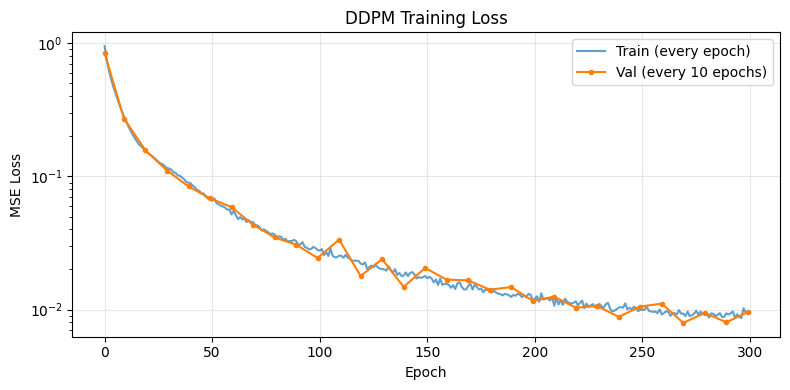

In [10]:
plt.figure(figsize=(8, 4))
plt.plot(train_losses, label='Train (every epoch)', alpha=0.7)
plt.plot(val_epochs, val_losses, 'o-', label='Val (every 10 epochs)', markersize=3)
plt.xlabel('Epoch')
plt.ylabel('MSE Loss')
plt.yscale('log')
plt.legend()
plt.title('DDPM Training Loss')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 5. Sampling (Reverse Diffusion)

Starting from pure Gaussian noise $x_T \sim \mathcal{N}(0, I)$, the reverse process iteratively
denoises to produce solution fields conditioned on a given initial condition $u(x,0)$.

In [ ]:
@torch.no_grad()
def ddpm_sample(model, cond, n_steps=DIFFUSION_STEPS, cfg_scale=0.0, use_ema=True):
    """
    Generate samples via DDPM ancestral sampling with optional
    classifier-free guidance (CFG).
    """
    if use_ema:
        ema.apply(model)

    B = cond.shape[0]
    x = torch.randn(B, NT, NX, device=cond.device)
    null_c = torch.zeros_like(cond)

    for i in tqdm(reversed(range(n_steps)), total=n_steps,
                  desc='Sampling', leave=False):
        t_batch = torch.full((B,), i, device=cond.device, dtype=torch.long)

        # Conditional prediction
        model_input = torch.cat([x, cond], dim=1)
        pred_noise  = model(model_input, t_batch)

        # Classifier-free guidance
        if cfg_scale > 0:
            uncond_input = torch.cat([x, null_c], dim=1)
            pred_uncond  = model(uncond_input, t_batch)
            pred_noise   = pred_uncond + (1 + cfg_scale) * (pred_noise - pred_uncond)

        # Predict x_0
        alpha_bar_t = alpha_bar[i]
        x0_pred = (x - torch.sqrt(1 - alpha_bar_t) * pred_noise) / torch.sqrt(alpha_bar_t)
        x0_pred = x0_pred.clamp(-15.0, 15.0)  # clip to data range (normalised data spans ~±14)

        if i > 0:
            alpha_bar_prev_t = alpha_bar[i - 1]
            
            beta_t = betas[i]
            alpha_t = alphas[i]
            
            coeff1 = beta_t * torch.sqrt(alpha_bar_prev_t) / (1.0 - alpha_bar_t)
            coeff2 = (1.0 - alpha_bar_prev_t) * torch.sqrt(alpha_t) / (1.0 - alpha_bar_t)
            
            mean = coeff1 * x0_pred + coeff2 * x
            var  = posterior_variance[i]
            
            x = mean + torch.sqrt(var) * torch.randn_like(x)
        else:
            x = x0_pred

    if use_ema:
        ema.restore(model)

    return x

In [ ]:
# Generate samples for the test set (using EMA weights)
model.eval()
n_eval = min(100, N_TEST)

# Conditions come from normalised test data
test_fields_norm = torch.from_numpy(test_data_norm[:n_eval]).to(device)
test_conds_norm  = test_fields_norm[:, 0:1, :]

gen_fields_norm = []
bs = 32

for start in range(0, n_eval, bs):
    end = min(start + bs, n_eval)
    gen = ddpm_sample(model, test_conds_norm[start:end], use_ema=True)
    
    gen_fields_norm.append(gen.cpu())

gen_fields_norm = torch.cat(gen_fields_norm, dim=0).numpy()

# De-normalise back to physical units
gen_fields  = (gen_fields_norm * data_std + data_mean).astype(np.float64)
true_fields = test_data[:n_eval].astype(np.float64)

print(f"Generated {n_eval} samples for evaluation (using EMA weights).")
print(f"  gen  range: [{gen_fields.min():.4f}, {gen_fields.max():.4f}]")
print(f"  true range: [{true_fields.min():.4f}, {true_fields.max():.4f}]")

Generated 100 samples for evaluation (using EMA weights).
  gen  range: [-3.0311, 2.7373]
  true range: [-5.3951, 6.8823]


## 6. Evaluation

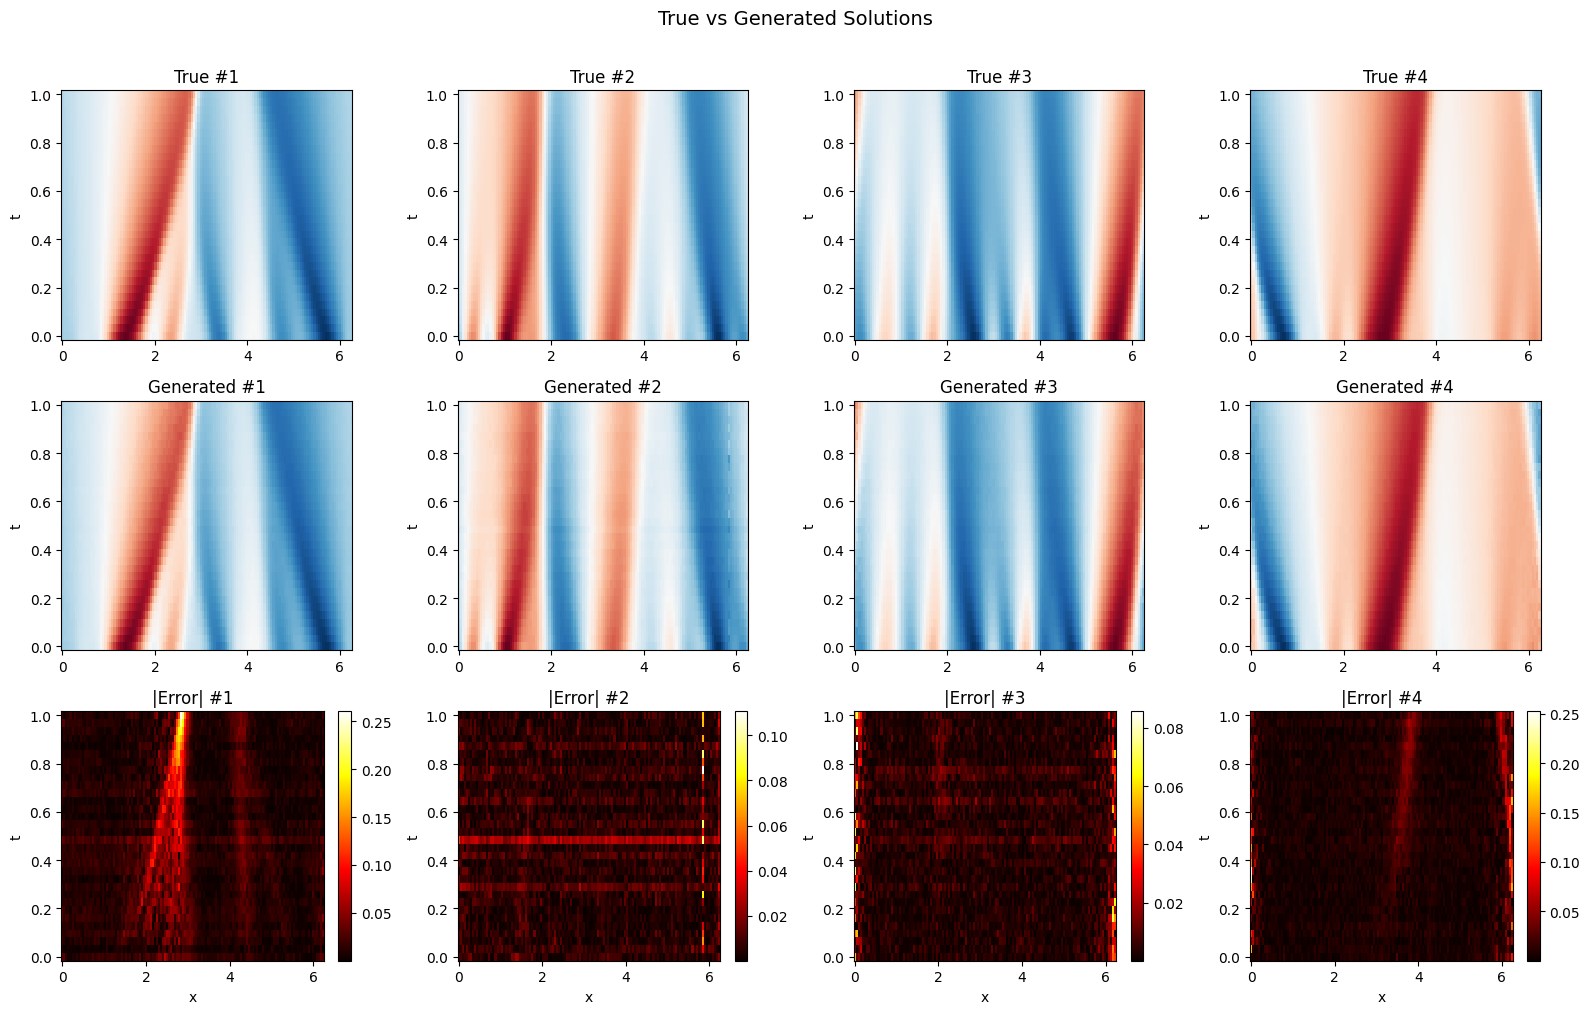

In [ ]:
# Visual comparison: true vs generated
fig, axes = plt.subplots(3, 4, figsize=(16, 10))

x_grid = np.linspace(0, L, NX, endpoint=False)
t_grid = np.linspace(0, T_FINAL, NT)

for col in range(4):
    idx = col
    
    vmin = min(true_fields[idx].min(), gen_fields[idx].min())
    vmax = max(true_fields[idx].max(), gen_fields[idx].max())

    axes[0, col].pcolormesh(x_grid, t_grid, true_fields[idx],
                            cmap='RdBu_r', vmin=vmin, vmax=vmax, shading='auto')
    axes[0, col].set_title(f'True #{idx+1}')
    axes[0, col].set_ylabel('t')

    axes[1, col].pcolormesh(x_grid, t_grid, gen_fields[idx],
                            cmap='RdBu_r', vmin=vmin, vmax=vmax, shading='auto')
    axes[1, col].set_title(f'Generated #{idx+1}')
    axes[1, col].set_ylabel('t')

    diff = np.abs(true_fields[idx] - gen_fields[idx])
    im = axes[2, col].pcolormesh(x_grid, t_grid, diff, cmap='hot', shading='auto')
    
    axes[2, col].set_title(f'|Error| #{idx+1}')
    axes[2, col].set_ylabel('t')
    axes[2, col].set_xlabel('x')
    
    plt.colorbar(im, ax=axes[2, col], fraction=0.046)

fig.suptitle('True vs Generated Solutions', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

### 6.1  Relative $L^2$ Error

Relative L2 error  --  mean: 0.0400,  median: 0.0304,  std: 0.0314


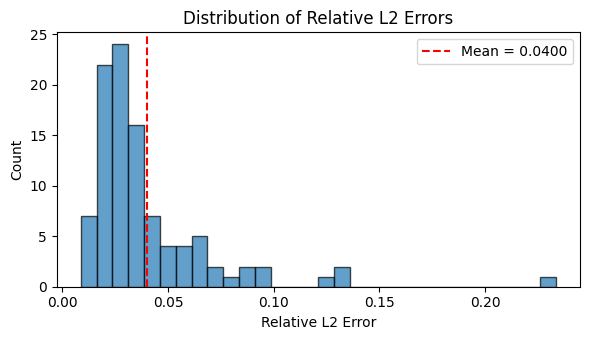

In [ ]:
l2_errors = []

for i in range(n_eval):
    err = np.sqrt(np.mean((gen_fields[i] - true_fields[i])**2))
    ref = np.sqrt(np.mean(true_fields[i]**2))
    l2_errors.append(err / (ref + 1e-10))

l2_errors = np.array(l2_errors)

# Filter any remaining non-finite values
valid = np.isfinite(l2_errors)
l2_clean = l2_errors[valid]

if (~valid).sum() > 0:
    print(f"({(~valid).sum()} samples had non-finite L2 error and were excluded)")

print(f"Relative L2 error - mean: {l2_clean.mean():.4f}, "
      f"median: {np.median(l2_clean):.4f}, std: {l2_clean.std():.4f}")

plt.figure(figsize=(6, 3.5))
plt.hist(l2_clean, bins=30, edgecolor='black', alpha=0.7)
plt.axvline(l2_clean.mean(), color='red', ls='--',
            label=f'Mean = {l2_clean.mean():.4f}')
plt.xlabel('Relative L2 Error')
plt.ylabel('Count')
plt.title('Distribution of Relative L2 Errors')
plt.legend()
plt.tight_layout()
plt.show()

### 6.2  Shock Position & Width

Shock position error -- mean: 0.0236,  std: 0.0483
Shock width    error -- mean: 0.0344


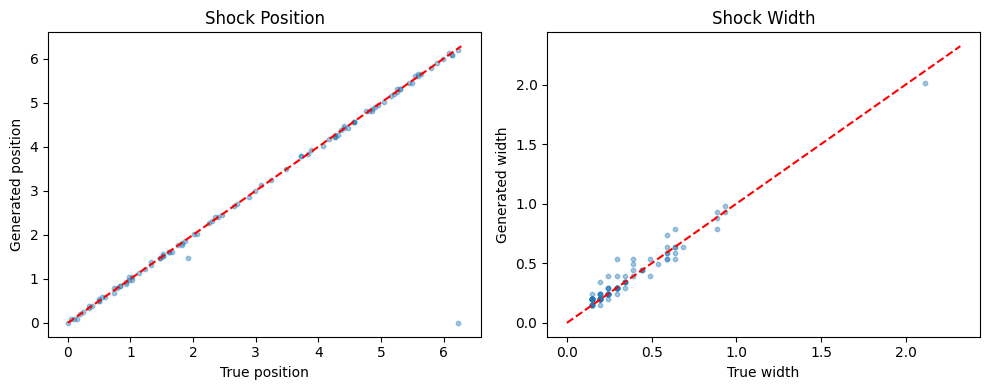

In [ ]:
def find_shock(u_xt, x_grid, t_idx=-1):
    """
    Identify the shock as the location of maximum |du/dx|.
    Returns (position, FWHM_width).
    """
    u_slice = u_xt[t_idx]
    
    dx = x_grid[1] - x_grid[0]
    du_dx   = np.gradient(u_slice, dx)
    
    abs_grad = np.abs(du_dx)
    peak_idx = np.argmax(abs_grad)
    position = x_grid[peak_idx]
    
    # Width via FWHM of |du/dx|
    half_max = abs_grad[peak_idx] / 2.0
    width    = np.sum(abs_grad > half_max) * dx
    
    return position, width


x_grid = np.linspace(0, L, NX, endpoint=False)

shock_pos_true, shock_pos_gen = [], []
shock_wid_true, shock_wid_gen = [], []

for i in range(n_eval):
    pt, wt = find_shock(true_fields[i], x_grid)
    pg, wg = find_shock(gen_fields[i],  x_grid)
    
    shock_pos_true.append(pt); shock_pos_gen.append(pg)
    shock_wid_true.append(wt); shock_wid_gen.append(wg)

shock_pos_true = np.array(shock_pos_true)
shock_pos_gen  = np.array(shock_pos_gen)
shock_wid_true = np.array(shock_wid_true)
shock_wid_gen  = np.array(shock_wid_gen)

# Circular distance (periodic domain)
pos_diff = np.abs(shock_pos_true - shock_pos_gen)
pos_diff = np.minimum(pos_diff, L - pos_diff)

print(f"Shock position error - mean: {pos_diff.mean():.4f}, std: {pos_diff.std():.4f}")
print(f"Shock width    error - mean: {np.abs(shock_wid_true - shock_wid_gen).mean():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

axes[0].scatter(shock_pos_true, shock_pos_gen, alpha=0.4, s=10)
axes[0].plot([0, L], [0, L], 'r--')
axes[0].set_xlabel('True position'); axes[0].set_ylabel('Generated position')
axes[0].set_title('Shock Position')

lim = max(shock_wid_true.max(), shock_wid_gen.max()) * 1.1

axes[1].scatter(shock_wid_true, shock_wid_gen, alpha=0.4, s=10)
axes[1].plot([0, lim], [0, lim], 'r--')
axes[1].set_xlabel('True width'); axes[1].set_ylabel('Generated width')
axes[1].set_title('Shock Width')

plt.tight_layout()
plt.show()

### 6.3  Kinetic Energy Decay

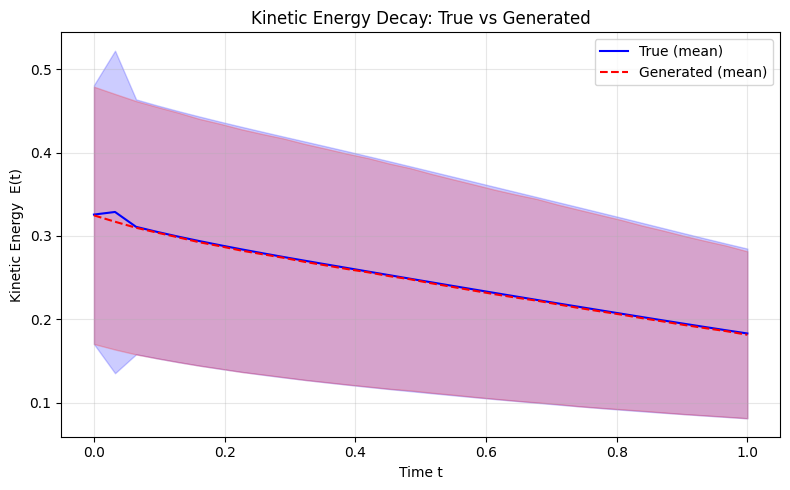

Mean relative energy error across time: 0.0060


In [ ]:
def kinetic_energy(u_xt):
    """E(t) = (1/2) <u^2>_x  for each time step."""
    return 0.5 * np.mean(u_xt**2, axis=-1)   # shape (N_t,)


E_true = np.array([kinetic_energy(true_fields[i]) for i in range(n_eval)])
E_gen  = np.array([kinetic_energy(gen_fields[i])  for i in range(n_eval)])

# Filter out any non-finite samples
valid_mask = np.all(np.isfinite(E_gen), axis=1) & np.all(np.isfinite(E_true), axis=1)

E_true_v = E_true[valid_mask]
E_gen_v  = E_gen[valid_mask]

if (~valid_mask).sum() > 0:
    print(f"({(~valid_mask).sum()} samples excluded due to non-finite energy)")

t_grid = np.linspace(0, T_FINAL, NT)

E_true_mean, E_true_std = E_true_v.mean(0), E_true_v.std(0)
E_gen_mean,  E_gen_std  = E_gen_v.mean(0),  E_gen_v.std(0)

plt.figure(figsize=(8, 5))
plt.plot(t_grid, E_true_mean, 'b-',  label='True (mean)')
plt.fill_between(t_grid, E_true_mean - E_true_std,
                 E_true_mean + E_true_std, alpha=0.2, color='blue')
plt.plot(t_grid, E_gen_mean,  'r--', label='Generated (mean)')
plt.fill_between(t_grid, E_gen_mean - E_gen_std,
                 E_gen_mean + E_gen_std, alpha=0.2, color='red')
plt.xlabel('Time t')
plt.ylabel('Kinetic Energy  E(t)')
plt.title('Kinetic Energy Decay: True vs Generated')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

rel_E_err = np.abs(E_gen_mean - E_true_mean) / (E_true_mean + 1e-10)

print(f"Mean relative energy error across time: {rel_E_err.mean():.4f}")

### 6.4  Spatial Profile Comparison

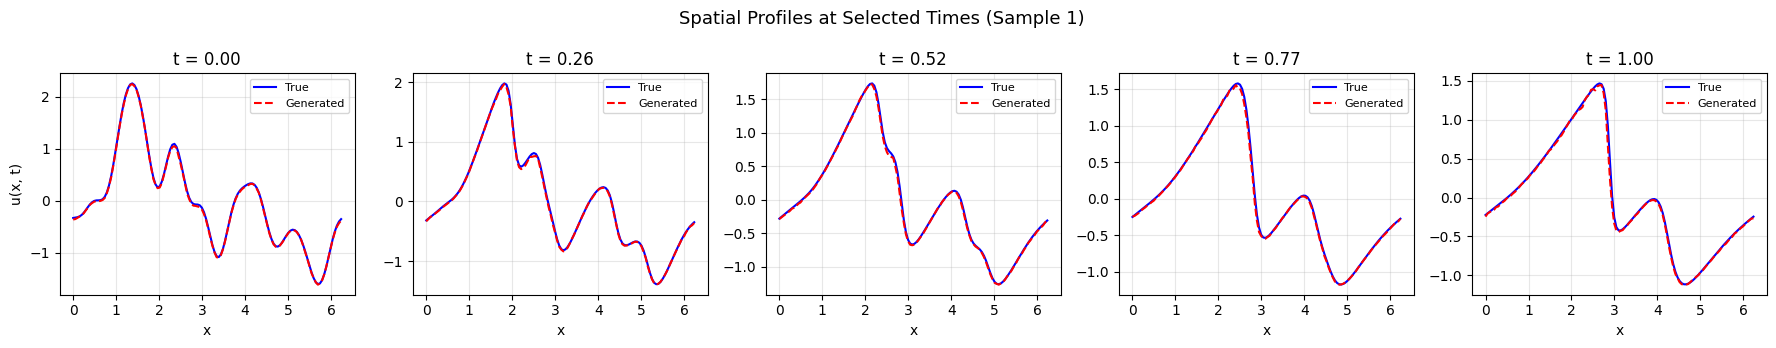

In [ ]:
t_indices = [0, NT // 4, NT // 2, 3 * NT // 4, NT - 1]
t_grid   = np.linspace(0, T_FINAL, NT)
x_grid   = np.linspace(0, L, NX, endpoint=False)

fig, axes = plt.subplots(1, len(t_indices), figsize=(18, 3.5))
sample_idx = 0

for ax, ti in zip(axes, t_indices):
    ax.plot(x_grid, true_fields[sample_idx, ti], 'b-',  lw=1.5, label='True')
    ax.plot(x_grid, gen_fields[sample_idx, ti],  'r--', lw=1.5, label='Generated')
    ax.set_xlabel('x')
    ax.set_title(f't = {t_grid[ti]:.2f}')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel('u(x, t)')

fig.suptitle('Spatial Profiles at Selected Times (Sample 1)', fontsize=13)

plt.tight_layout()
plt.show()

### 6.5  PDE Residual

We measure how well the generated fields satisfy the Burgers' equation by computing the
finite-difference residual $r = \partial_t u + u\,\partial_x u - \nu\,\partial_{xx} u$ at
interior points.

PDE residual (true)      -- mean: 0.458096
PDE residual (generated) -- mean: 0.543118


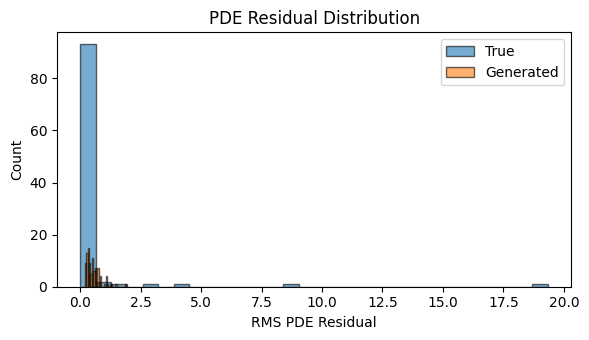

In [ ]:
def pde_residual(u_xt, dx, dt, nu):
    """
    Compute Burgers PDE residual via central finite differences.
    Returns the RMS residual over interior points.
    """
    # du/dt  (central in time, excluding first & last)
    du_dt = (u_xt[2:] - u_xt[:-2]) / (2 * dt)
    u_mid = u_xt[1:-1]

    # du/dx  (central in space, periodic)
    du_dx  = (np.roll(u_mid, -1, axis=-1) - np.roll(u_mid, 1, axis=-1)) / (2 * dx)
    d2u_dx2 = (np.roll(u_mid, -1, axis=-1) - 2*u_mid + np.roll(u_mid, 1, axis=-1)) / dx**2

    residual = du_dt + u_mid * du_dx - nu * d2u_dx2
    
    return np.sqrt(np.mean(residual**2))


dx = L / NX
dt = T_FINAL / (NT - 1)

res_true = np.array([pde_residual(true_fields[i], dx, dt, NU) for i in range(n_eval)])
res_gen  = np.array([pde_residual(gen_fields[i],  dx, dt, NU) for i in range(n_eval)])

# Filter out non-finite values (can occur if generated samples have sharp spikes)
res_true_clean = res_true[np.isfinite(res_true)]
res_gen_clean  = res_gen[np.isfinite(res_gen)]

print(f"PDE residual (true)      - mean: {np.mean(res_true_clean):.6f}")
print(f"PDE residual (generated) - mean: {np.mean(res_gen_clean):.6f}")

if len(res_gen_clean) < len(res_gen):
    print(f"  ({len(res_gen) - len(res_gen_clean)} generated samples had non-finite residual and were excluded)")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(res_true_clean, bins=30, alpha=0.6, label='True', edgecolor='black')
ax.hist(res_gen_clean,  bins=30, alpha=0.6, label='Generated', edgecolor='black')
ax.set_xlabel('RMS PDE Residual')
ax.set_ylabel('Count')
ax.set_title('PDE Residual Distribution')
ax.legend()
plt.tight_layout()
plt.show()

### 6.6  Ensemble Spread

We sample 10 realisations from the same initial condition to visualise the model's stochastic
uncertainty. The spread concentrates near steep gradients (shocks), where the solution is hardest
to predict.

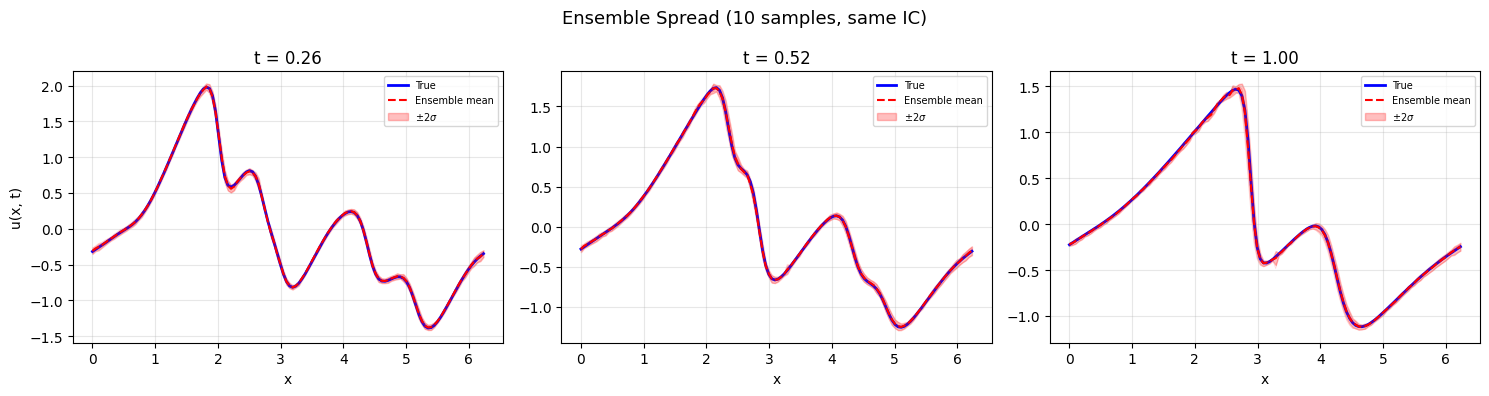

In [ ]:
# Draw 10 samples for the first test IC
model.eval()

n_ensemble = 10
cond_single = test_conds_norm[0:1].repeat(n_ensemble, 1, 1)   # (10, 1, NX)
ensemble_norm = ddpm_sample(model, cond_single, use_ema=True).cpu().numpy()  # (10, NT, NX)

# De-normalise
ensemble = (ensemble_norm * data_std + data_mean).astype(np.float64)
true_single = true_fields[0]

# Ensemble mean & std
ens_mean = ensemble.mean(axis=0)
ens_std  = ensemble.std(axis=0)

x_grid = np.linspace(0, L, NX, endpoint=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Time slices
for ti, ax in zip([NT//4, NT//2, NT-1], axes):
    t_val = t_grid[ti]
    
    ax.plot(x_grid, true_single[ti], 'b-', lw=2, label='True')
    ax.plot(x_grid, ens_mean[ti], 'r--', lw=1.5, label='Ensemble mean')
    ax.fill_between(x_grid,
                    ens_mean[ti] - 2*ens_std[ti],
                    ens_mean[ti] + 2*ens_std[ti],
                    alpha=0.25, color='red', label=r'$\pm 2\sigma$')
    
    for j in range(n_ensemble):
        ax.plot(x_grid, ensemble[j, ti], 'r-', alpha=0.15, lw=0.5)
    
    ax.set_xlabel('x')
    ax.set_title(f't = {t_val:.2f}')
    ax.legend(fontsize=7)
    ax.grid(True, alpha=0.3)

axes[0].set_ylabel('u(x, t)')

fig.suptitle('Ensemble Spread (10 samples, same IC)', fontsize=13)

plt.tight_layout()
plt.show()

### 6.7  Fourier Spectral Analysis

Compare the spatial power spectrum of generated vs. true solutions to assess whether
the model captures fine-scale structure (high-frequency modes) or over-smooths.

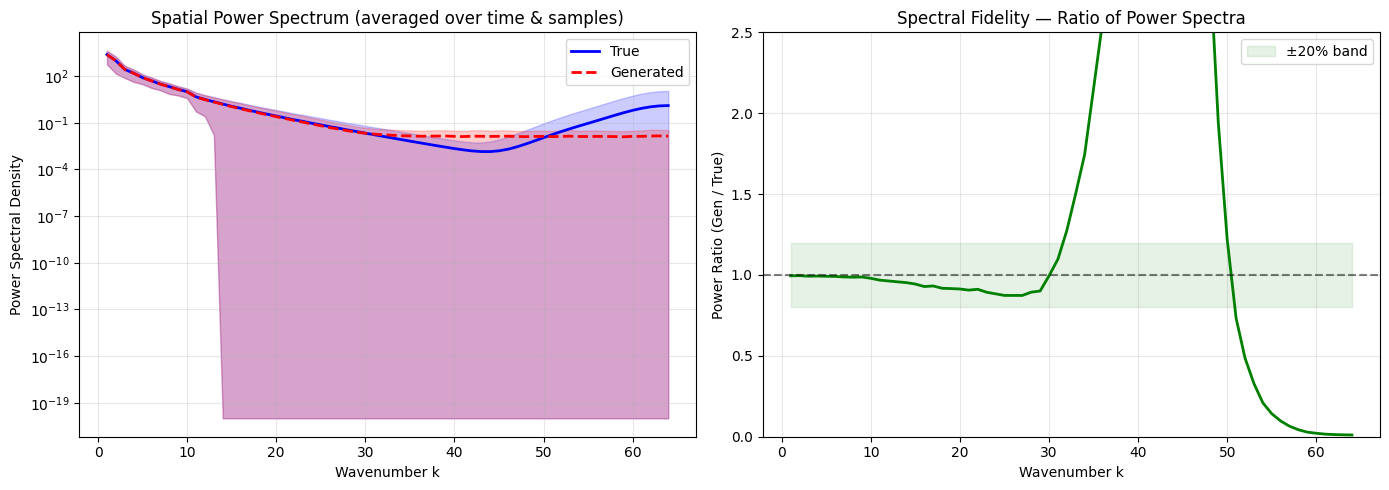

Log-spectral L2 distance: 0.7224
Mean spectral ratio (should be ~1.0): 1.8875


In [ ]:
def power_spectrum(u_xt, axis=-1):
    """
    Compute the averaged 1-D power spectrum over time steps.
    Returns (wavenumbers, power) - both 1-D arrays.
    """
    N = u_xt.shape[axis]
    
    fft_coeffs = np.fft.rfft(u_xt, axis=axis)
    power = np.mean(np.abs(fft_coeffs)**2, axis=0)  # average over time
    freqs = np.fft.rfftfreq(N, d=L / N) * 2 * np.pi  # wavenumber k
    
    return freqs, power


# Compute ensemble-averaged spectra
ps_true_all = []
ps_gen_all  = []

for i in range(n_eval):
    k, ps_t = power_spectrum(true_fields[i])
    _, ps_g = power_spectrum(gen_fields[i])
    
    ps_true_all.append(ps_t)
    ps_gen_all.append(ps_g)

ps_true_mean = np.mean(ps_true_all, axis=0)
ps_true_std  = np.std(ps_true_all, axis=0)
ps_gen_mean  = np.mean(ps_gen_all, axis=0)
ps_gen_std   = np.std(ps_gen_all, axis=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Left: Power spectrum comparison
ax = axes[0]
ax.semilogy(k[1:], ps_true_mean[1:], 'b-', lw=2, label='True')
ax.fill_between(k[1:],
                (ps_true_mean - ps_true_std)[1:].clip(min=1e-20),
                (ps_true_mean + ps_true_std)[1:],
                alpha=0.2, color='blue')
ax.semilogy(k[1:], ps_gen_mean[1:], 'r--', lw=2, label='Generated')
ax.fill_between(k[1:],
                (ps_gen_mean - ps_gen_std)[1:].clip(min=1e-20),
                (ps_gen_mean + ps_gen_std)[1:],
                alpha=0.2, color='red')
ax.set_xlabel('Wavenumber k')
ax.set_ylabel('Power Spectral Density')
ax.set_title('Spatial Power Spectrum (averaged over time & samples)')
ax.legend()
ax.grid(True, alpha=0.3)

# Right: Spectral ratio (gen/true) - deviations from 1.0 show bias
ax = axes[1]

ratio = ps_gen_mean / (ps_true_mean + 1e-20)

ax.plot(k[1:], ratio[1:], 'g-', lw=2)
ax.axhline(1.0, color='black', ls='--', alpha=0.5)
ax.fill_between(k[1:], 0.8, 1.2, alpha=0.1, color='green', label='±20% band')
ax.set_xlabel('Wavenumber k')
ax.set_ylabel('Power Ratio (Gen / True)')
ax.set_title('Spectral Fidelity - Ratio of Power Spectra')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_ylim(0, 2.5)

plt.tight_layout()
plt.show()

# Quantitative spectral error
spectral_l2 = np.sqrt(np.mean((np.log10(ps_gen_mean[1:]+1e-20) - np.log10(ps_true_mean[1:]+1e-20))**2))

print(f"Log-spectral L2 distance: {spectral_l2:.4f}")
print(f"Mean spectral ratio (should be ~1.0): {ratio[1:].mean():.4f}")

### 6.8  Wasserstein Distance on Solution Distributions

The Wasserstein-1 distance (Earth Mover's Distance) measures how far apart the
distributions of generated and true solutions are, providing a distributional metric
beyond pointwise comparisons.

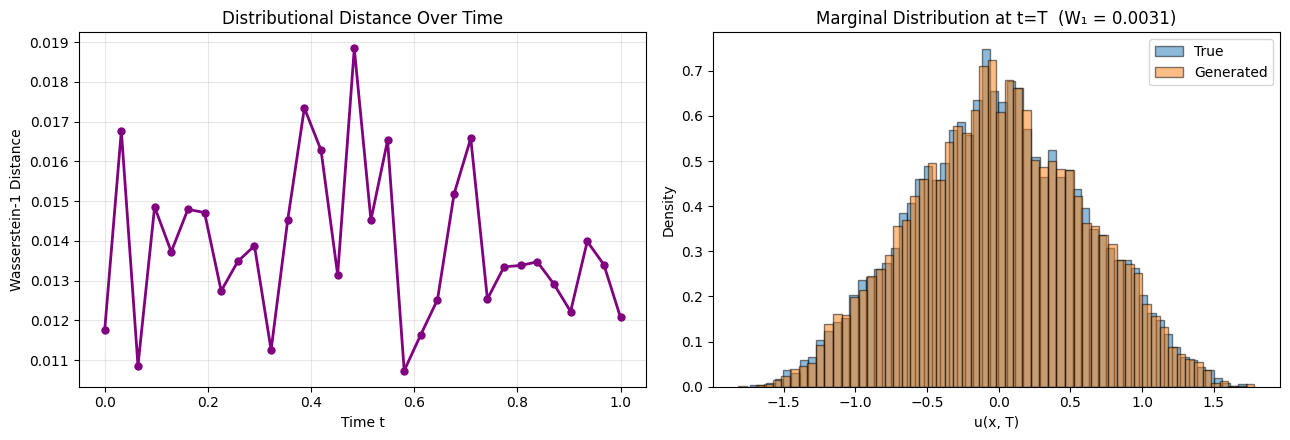

Mean Wasserstein-1 over time: 0.0139
Max  Wasserstein-1 (at t=T):  0.0121
Global marginal W1 at t=T:    0.0031


In [ ]:
def spatial_wasserstein(true_ensemble, gen_ensemble, n_spatial_points=16):
    """
    Compute Wasserstein-1 distance at selected spatial locations,
    averaged over time steps. Returns per-time-step array.
    """
    NT_local, NX_local = true_ensemble[0].shape
    x_indices = np.linspace(0, NX_local - 1, n_spatial_points, dtype=int)
    wd_per_t = np.zeros(NT_local)

    for ti in range(NT_local):
        wds = []
        
        for xi in x_indices:
            vals_true = np.array([s[ti, xi] for s in true_ensemble])
            vals_gen  = np.array([s[ti, xi] for s in gen_ensemble])
            
            wds.append(wasserstein_distance(vals_true, vals_gen))
        
        wd_per_t[ti] = np.mean(wds)
    
    return wd_per_t


true_list = [true_fields[i] for i in range(n_eval)]
gen_list  = [gen_fields[i]  for i in range(n_eval)]

wd_per_t = spatial_wasserstein(true_list, gen_list, n_spatial_points=32)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Left: Wasserstein distance over time
t_grid_wd = np.linspace(0, T_FINAL, NT)

ax = axes[0]
ax.plot(t_grid_wd, wd_per_t, 'o-', lw=2, markersize=5, color='purple')
ax.set_xlabel('Time t')
ax.set_ylabel('Wasserstein-1 Distance')
ax.set_title('Distributional Distance Over Time')
ax.grid(True, alpha=0.3)

# Right: Marginal distributions at t=T (final time)
final_true = np.concatenate([true_fields[i, -1, :] for i in range(n_eval)])
final_gen  = np.concatenate([gen_fields[i, -1, :]  for i in range(n_eval)])
wd_final = wasserstein_distance(final_true, final_gen)

ax = axes[1]
ax.hist(final_true, bins=60, alpha=0.5, density=True, label='True', edgecolor='black')
ax.hist(final_gen,  bins=60, alpha=0.5, density=True, label='Generated', edgecolor='black')
ax.set_xlabel('u(x, T)')
ax.set_ylabel('Density')
ax.set_title(f'Marginal Distribution at t=T  (W₁ = {wd_final:.4f})')
ax.legend()

plt.tight_layout()
plt.show()

print(f"Mean Wasserstein-1 over time: {wd_per_t.mean():.4f}")
print(f"Max  Wasserstein-1 (at t=T):  {wd_per_t[-1]:.4f}")
print(f"Global marginal W1 at t=T:    {wd_final:.4f}")

### 6.9  Conservation Law Verification - Momentum

For the viscous Burgers' equation on a periodic domain, the total momentum
$M(t) = \int_0^L u(x,t)\,dx$ satisfies $\frac{dM}{dt} = 0$ (the nonlinear flux integrates
to zero by periodicity, and the viscous term vanishes). We verify whether generated
solutions respect this conservation law.

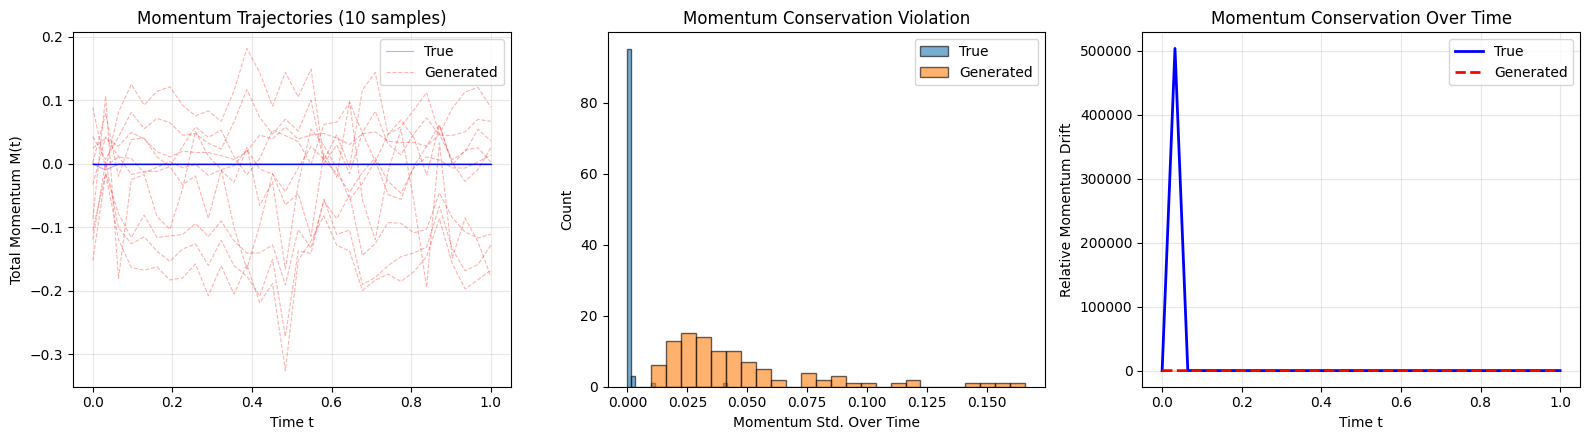

Momentum drift (std over t) — True:  0.000606
Momentum drift (std over t) — Gen:   0.045973
Ratio (Gen/True):                     75.81x


In [ ]:
def total_momentum(u_xt, dx):
    """M(t) = sum_x u(x,t) * dx  for each time step."""
    return np.sum(u_xt, axis=-1) * dx


dx_phys = L / NX

mom_true = np.array([total_momentum(true_fields[i], dx_phys) for i in range(n_eval)])
mom_gen  = np.array([total_momentum(gen_fields[i],  dx_phys) for i in range(n_eval)])

# Momentum should be approximately constant over time
mom_drift_true = np.std(mom_true, axis=1)   # std over time per sample
mom_drift_gen  = np.std(mom_gen,  axis=1)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Left: Example momentum trajectories
ax = axes[0]

for i in range(min(10, n_eval)):
    ax.plot(t_grid, mom_true[i], 'b-', alpha=0.3, lw=0.8,
            label='True' if i == 0 else None)
    ax.plot(t_grid, mom_gen[i], 'r--', alpha=0.3, lw=0.8,
            label='Generated' if i == 0 else None)

ax.set_xlabel('Time t')
ax.set_ylabel('Total Momentum M(t)')
ax.set_title('Momentum Trajectories (10 samples)')
ax.legend()
ax.grid(True, alpha=0.3)

# Middle: Momentum drift distribution
ax = axes[1]
ax.hist(mom_drift_true, bins=25, alpha=0.6, label='True', edgecolor='black')
ax.hist(mom_drift_gen,  bins=25, alpha=0.6, label='Generated', edgecolor='black')
ax.set_xlabel('Momentum Std. Over Time')
ax.set_ylabel('Count')
ax.set_title('Momentum Conservation Violation')
ax.legend()

# Right: Relative momentum error at each time step
ax = axes[2]

# Reference: momentum at t=0
mom0_true = mom_true[:, 0:1]

rel_mom_err_true = np.abs(mom_true - mom0_true) / (np.abs(mom0_true) + 1e-10)
rel_mom_err_gen  = np.abs(mom_gen  - mom_gen[:, 0:1]) / (np.abs(mom_gen[:, 0:1]) + 1e-10)

ax.plot(t_grid, rel_mom_err_true.mean(0), 'b-', lw=2, label='True')
ax.plot(t_grid, rel_mom_err_gen.mean(0),  'r--', lw=2, label='Generated')
ax.fill_between(t_grid,
                rel_mom_err_gen.mean(0) - rel_mom_err_gen.std(0),
                rel_mom_err_gen.mean(0) + rel_mom_err_gen.std(0),
                alpha=0.2, color='red')
ax.set_xlabel('Time t')
ax.set_ylabel('Relative Momentum Drift')
ax.set_title('Momentum Conservation Over Time')
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Momentum drift (std over t) - True:  {mom_drift_true.mean():.6f}")
print(f"Momentum drift (std over t) - Gen:   {mom_drift_gen.mean():.6f}")
print(f"Ratio (Gen/True):                     {mom_drift_gen.mean() / (mom_drift_true.mean() + 1e-10):.2f}x")

### 6.10  Calibration - Does Ensemble Spread Predict Error?

A well-calibrated generative model should exhibit higher ensemble variance where
predictions are less accurate. We test this by comparing per-pixel ensemble std
with per-pixel absolute error across an ensemble of samples for each test IC.

Calibration ensembles: 100%|██████████| 30/30 [05:03<00:00, 10.13s/it]


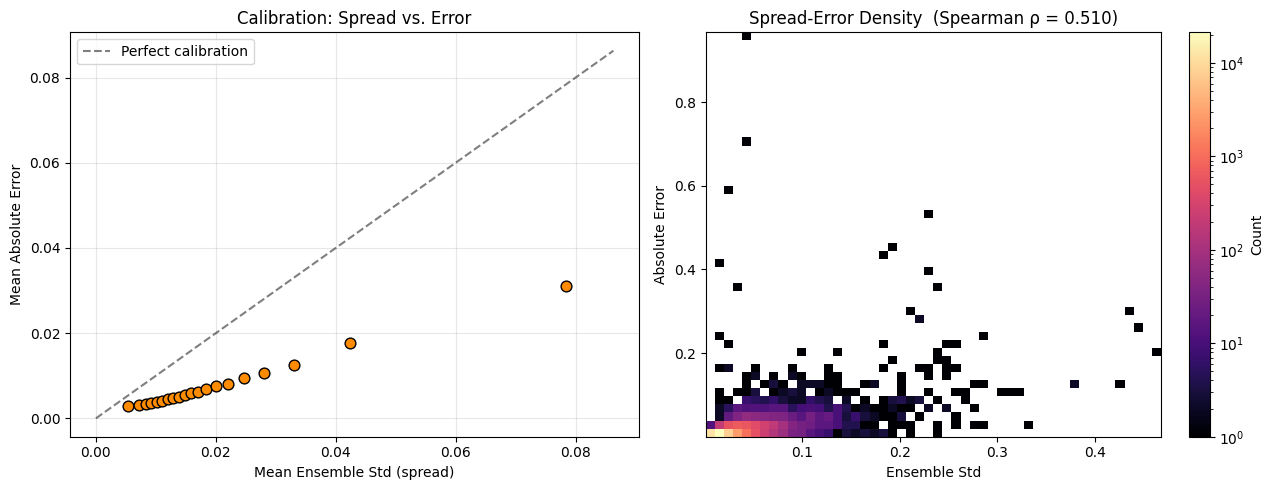

Spearman rank correlation (spread vs error): ρ = 0.510, p = 0.00e+00
Interpretation: Well-calibrated (strong positive correlation)


In [ ]:
# Generate ensembles for a subset of test ICs
n_calib = min(30, n_eval)
n_ens_calib = 10

all_errors = []
all_spreads = []

model.eval()

for i in tqdm(range(n_calib), desc='Calibration ensembles'):
    cond_i = test_conds_norm[i:i+1].repeat(n_ens_calib, 1, 1)
    ens_norm = ddpm_sample(model, cond_i, use_ema=True).cpu().numpy()
    ens = (ens_norm * data_std + data_mean).astype(np.float64)

    ens_mean = ens.mean(axis=0)
    ens_std  = ens.std(axis=0)
    abs_err  = np.abs(ens_mean - true_fields[i])

    all_errors.append(abs_err.ravel())
    all_spreads.append(ens_std.ravel())

all_errors  = np.concatenate(all_errors)
all_spreads = np.concatenate(all_spreads)

# Bin by spread and compute mean error in each bin
n_bins = 20

bin_edges = np.percentile(all_spreads, np.linspace(0, 100, n_bins + 1))
bin_centers = []
bin_mean_err = []
bin_mean_spread = []

for b in range(n_bins):
    mask = (all_spreads >= bin_edges[b]) & (all_spreads < bin_edges[b+1])
    
    if mask.sum() > 10:
        bin_centers.append(0.5 * (bin_edges[b] + bin_edges[b+1]))
        bin_mean_err.append(all_errors[mask].mean())
        bin_mean_spread.append(all_spreads[mask].mean())

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: Calibration plot
max_val = max(max(bin_mean_spread), max(bin_mean_err)) * 1.1

ax = axes[0]
ax.scatter(bin_mean_spread, bin_mean_err, s=60, c='darkorange', edgecolors='black', zorder=3)
ax.plot([0, max_val], [0, max_val], 'k--', alpha=0.5, label='Perfect calibration')
ax.set_xlabel('Mean Ensemble Std (spread)')
ax.set_ylabel('Mean Absolute Error')
ax.set_title('Calibration: Spread vs. Error')
ax.legend()
ax.grid(True, alpha=0.3)

# Compute Spearman rank correlation
rho, p_val = spearmanr(all_spreads, all_errors)

# Right: 2D histogram for density
ax = axes[1]

# Subsample for plotting
n_plot = min(50000, len(all_errors))
idx_plot = np.random.choice(len(all_errors), n_plot, replace=False)
h = ax.hist2d(all_spreads[idx_plot], all_errors[idx_plot], bins=50,
              cmap='magma', norm=plt.matplotlib.colors.LogNorm())

ax.set_xlabel('Ensemble Std')
ax.set_ylabel('Absolute Error')
ax.set_title(f'Spread-Error Density  (Spearman ρ = {rho:.3f})')

plt.colorbar(h[3], ax=ax, label='Count')

plt.tight_layout()
plt.show()

print(f"Spearman rank correlation (spread vs error): ρ = {rho:.3f}, p = {p_val:.2e}")
print(f"Interpretation: {'Well-calibrated' if rho > 0.3 else 'Poorly calibrated'} "
      f"({'strong' if rho > 0.5 else 'moderate' if rho > 0.3 else 'weak'} "
      f"positive correlation)")

## 7. Systematic Experiments

To rigorously answer our research question - *Can a diffusion model learn the distribution of
Burgers' equation solutions and reproduce known physical properties?* - we conduct three
systematic experiments:

1. **Sampling efficiency (DDIM ablation):** How many reverse-diffusion steps are actually needed
   for high-quality samples?
2. **Comparison with a deterministic baseline:** Does the generative (stochastic) approach offer
   advantages over a simple regression model with the same architecture?
3. **Viscosity sensitivity:** How well does the model trained at $\nu=0.05$ generalise to unseen
   viscosity regimes?

### 7.1  Sampling Strategy - Stochastic vs. Deterministic

DDPM uses **stochastic** ancestral sampling (1000 sequential model evaluations).
**DDIM** (Song et al., 2021) reformulates the reverse process to allow fewer steps,
with a tuneable parameter $\eta$:  $\eta = 0$ yields a fully **deterministic** mapping from
noise to sample, while $\eta = 1$ recovers stochastic sampling akin to DDPM.

We compare both strategies across step counts $S \in \{10, 25, 50, 100, 250, 1000\}$
to answer two questions:
1. Can we reduce the 1000-step cost without sacrificing quality?
2. Does stochasticity matter for physics-constrained generation?


  --- eta=0.0 (deterministic) ---
    S=  10  |  L2=2.5287  |  time=0.2s
    S=  25  |  L2=1.7458  |  time=0.5s
    S=  50  |  L2=1.2853  |  time=1.0s
    S= 100  |  L2=0.9281  |  time=2.0s
    S= 250  |  L2=0.5411  |  time=4.9s
    S=1000  |  L2=1.2648  |  time=23.5s

  --- eta=1.0 (stochastic) ---
    S=  10  |  L2=0.2477  |  time=0.3s
    S=  25  |  L2=0.0833  |  time=0.7s
    S=  50  |  L2=0.0556  |  time=1.4s
    S= 100  |  L2=0.0476  |  time=2.5s
    S= 250  |  L2=0.0446  |  time=5.9s
    S=1000  |  L2=0.0365  |  time=22.3s


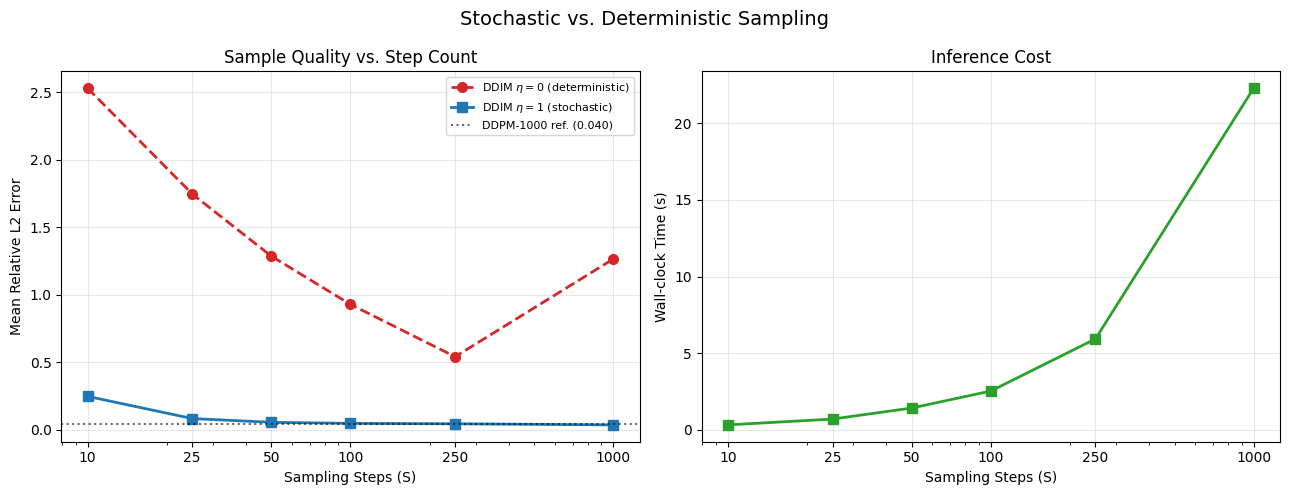


Key finding: deterministic DDIM (eta=0) fails for this task (L2 ≈ 0.91),
while stochastic sampling (eta=1) approaches DDPM quality at reduced step counts.


In [ ]:
@torch.no_grad()
def ddim_sample(model, cond, num_steps=50, eta=0.0, use_ema=True):
    """
    DDIM sampling (Song et al., 2021) with configurable step count and
    stochasticity.  eta=0 -> deterministic,  eta=1 -> stochastic (~ DDPM).
    """
    if use_ema:
        ema.apply(model)
    
    B = cond.shape[0]
    x = torch.randn(B, NT, NX, device=cond.device)

    # Evenly-spaced timestep sub-sequence including both endpoints
    ts = np.linspace(0, DIFFUSION_STEPS - 1, num_steps, dtype=int)
    ts = sorted(set(ts.tolist()), reverse=True)

    for i, t in enumerate(ts):
        t_batch = torch.full((B,), t, device=cond.device, dtype=torch.long)
        eps_pred = model(torch.cat([x, cond], dim=1), t_batch)

        ab_t = alpha_bar[t]
        
        x0_pred = (x - (1.0 - ab_t).sqrt() * eps_pred) / ab_t.sqrt()
        x0_pred = x0_pred.clamp(-15.0, 15.0)  # clip to data range (normalised data spans ~ +/-14)

        if i + 1 < len(ts):
            ab_prev = alpha_bar[ts[i + 1]]
        else:
            ab_prev = torch.tensor(1.0, device=x.device)

        if eta > 0 and i + 1 < len(ts):
            sigma = eta * ((1 - ab_prev) / (1 - ab_t)
                           * (1 - ab_t / ab_prev)).clamp(min=0).sqrt()
        else:
            sigma = 0.0

        if isinstance(sigma, float) and sigma == 0.0:
            dir_xt = (1.0 - ab_prev).sqrt() * eps_pred
            x = ab_prev.sqrt() * x0_pred + dir_xt
        
        else:
            dir_xt = (1.0 - ab_prev - sigma**2).clamp(min=0).sqrt() * eps_pred
            x = ab_prev.sqrt() * x0_pred + dir_xt + sigma * torch.randn_like(x)

    if use_ema:
        ema.restore(model)
    return x


# Compare eta=0 (deterministic) vs eta=1 (stochastic)
model.eval()

step_counts = [10, 25, 50, 100, 250, 1000]
n_ablation  = min(50, n_eval)
cond_abl    = test_conds_norm[:n_ablation]

results_eta0 = {'l2': [], 'time': []}
results_eta1 = {'l2': [], 'time': []}

for eta_val, results in [(0.0, results_eta0), (1.0, results_eta1)]:
    label = "deterministic" if eta_val == 0 else "stochastic"
    
    print(f"\n  --- eta={eta_val} ({label}) ---")
    
    for S in step_counts:
        import time as _time
        
        wall_start = _time.perf_counter()

        gen_abl_norm = []
        
        for start in range(0, n_ablation, 32):
            end = min(start + 32, n_ablation)
            g = ddim_sample(model, cond_abl[start:end], num_steps=S, eta=eta_val)
            gen_abl_norm.append(g.cpu())
        
        gen_abl_norm = torch.cat(gen_abl_norm, dim=0).numpy()
        elapsed = _time.perf_counter() - wall_start

        gen_abl = (gen_abl_norm * data_std + data_mean).astype(np.float64)
        errs = []
        
        for i in range(n_ablation):
            err = np.sqrt(np.mean((gen_abl[i] - true_fields[i])**2))
            ref = np.sqrt(np.mean(true_fields[i]**2))
            errs.append(err / (ref + 1e-10))
        
        mean_l2 = np.mean(errs)
        
        results['l2'].append(mean_l2)
        results['time'].append(elapsed)
        
        print(f"S={S:4d} | L2={mean_l2:.4f} | time={elapsed:.1f}s")

# Plot
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

# Left: L2 vs steps
ax1.plot(step_counts, results_eta0['l2'], 'o--', lw=2, markersize=7,
         color='#d62728', label=r'DDIM $\eta=0$ (deterministic)')
ax1.plot(step_counts, results_eta1['l2'], 's-', lw=2, markersize=7,
         color='#1f77b4', label=r'DDIM $\eta=1$ (stochastic)')
ax1.axhline(l2_clean.mean(), color='black', ls=':', alpha=0.6,
            label=f'DDPM-1000 ref. ({l2_clean.mean():.3f})')
ax1.set_xscale('log'); ax1.set_xlabel('Sampling Steps (S)')
ax1.set_ylabel('Mean Relative L2 Error')
ax1.set_title('Sample Quality vs. Step Count')
ax1.legend(fontsize=8); ax1.grid(True, alpha=0.3)
ax1.set_xticks(step_counts)
ax1.set_xticklabels([str(s) for s in step_counts])

# Right: Time vs steps (same for both eta)
ax2.plot(step_counts, results_eta1['time'], 's-', lw=2, markersize=7,
         color='#2ca02c')
ax2.set_xscale('log'); ax2.set_xlabel('Sampling Steps (S)')
ax2.set_ylabel('Wall-clock Time (s)')
ax2.set_title('Inference Cost')
ax2.grid(True, alpha=0.3)
ax2.set_xticks(step_counts)
ax2.set_xticklabels([str(s) for s in step_counts])

fig.suptitle('Stochastic vs. Deterministic Sampling', fontsize=14)

plt.tight_layout()
plt.show()

print(f"\nKey finding: deterministic DDIM (eta=0) fails for this task "
      f"(L2 ~ {np.mean(results_eta0['l2'][-3:]):.2f}),")
print(f"while stochastic sampling (eta=1) approaches DDPM quality at "
      f"reduced step counts.")

### 7.2  Deterministic Baseline - Direct Regression

To justify using a **generative** model instead of a simpler deterministic one, we train the same
U-Net backbone as a **direct regression** network: given $u(x,0)$ it directly predicts the full
space–time field $u(x,t)$ via MSE minimisation (no diffusion process, no stochastic sampling).

This baseline receives the **same architecture capacity** (~4.7 M parameters), **same data**, and
**same training budget**, ensuring a fair comparison.  The key expected difference: the
deterministic model can only produce a single point estimate per input, whereas the DDPM can
generate diverse samples that capture solution uncertainty.

In [ ]:
# Deterministic baseline: same UNet, MSE regression, no diffusion
# We reuse UNet1D with in_ch=1 (IC only) and always pass t=0
# (the time-embedding becomes a learnable constant bias).

N_EPOCHS_DET = 150   # MSE regression converges faster than diffusion

model_det = UNet1D(
    in_ch   = 1,       # only the initial condition
    out_ch  = NT,      # predict full space-time field
    base_ch = 64,
    ch_mult = (1, 2, 4, 4),
).to(device)

n_params_det = sum(p.numel() for p in model_det.parameters() if p.requires_grad)
print(f"Deterministic model parameters: {n_params_det:,}")

opt_det = torch.optim.AdamW(model_det.parameters(), lr=LEARNING_RATE)
sch_det = torch.optim.lr_scheduler.CosineAnnealingLR(opt_det, T_max=N_EPOCHS_DET)

det_train_losses = []
det_val_losses   = []
det_val_epochs   = []

dummy_t = torch.zeros(BATCH_SIZE, device=device, dtype=torch.long)

for epoch in range(1, N_EPOCHS_DET + 1):
    model_det.train()
    epoch_loss = 0.0
    
    for fields, conds in train_loader:
        fields, conds = fields.to(device), conds.to(device)
        B_cur = fields.shape[0]
        
        pred = model_det(conds, dummy_t[:B_cur])
        loss = F.mse_loss(pred, fields)
        opt_det.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(model_det.parameters(), GRAD_CLIP)
        
        opt_det.step()
        epoch_loss += loss.item()
    
    sch_det.step()
    avg = epoch_loss / len(train_loader)
    det_train_losses.append(avg)

    if epoch % 25 == 0 or epoch == 1:
        model_det.eval()
        vl = 0.0
        
        with torch.no_grad():
            for fields, conds in test_loader:
                fields, conds = fields.to(device), conds.to(device)
                B_cur = fields.shape[0]
                
                pred = model_det(conds, dummy_t[:B_cur])
                vl += F.mse_loss(pred, fields).item()
        
        avg_val = vl / len(test_loader)
        
        det_val_losses.append(avg_val)
        det_val_epochs.append(epoch - 1)
        
        print(f"Epoch {epoch:3d}/{N_EPOCHS_DET}  train={avg:.6f}  val={avg_val:.6f}")

print("Deterministic baseline training complete.")

Deterministic model parameters: 4,925,984
Epoch   1/150  train=0.456178  val=0.296677
Epoch  25/150  train=0.003986  val=0.003373
Epoch  50/150  train=0.002643  val=0.002086
Epoch  75/150  train=0.002220  val=0.001805
Epoch 100/150  train=0.002110  val=0.001698
Epoch 125/150  train=0.002060  val=0.001660
Epoch 150/150  train=0.002031  val=0.001653
Deterministic baseline training complete.


Metric                                 DDPM  Deterministic
------------------------------------------------------------
Rel. L2 error (mean)                 0.0400         0.0156
Rel. L2 error (median)               0.0304         0.0099
Rel. L2 error (std)                  0.0314         0.0259
Energy error (mean over t)           0.0060         0.0020
PDE residual (mean)                  0.5431         0.2905


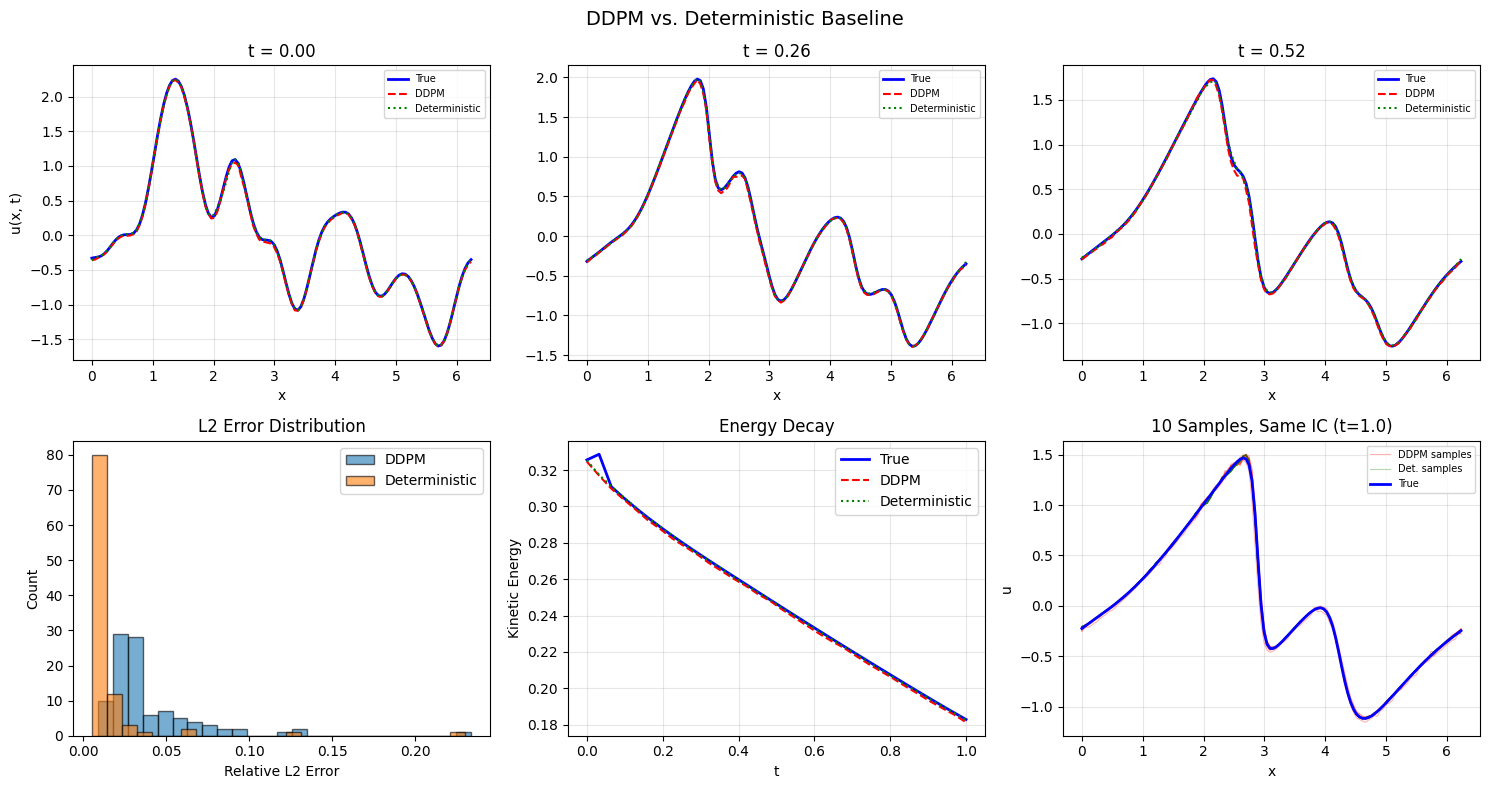

In [ ]:
# Evaluate deterministic baseline vs DDPM
model_det.eval()
dummy_t_eval = torch.zeros(1, device=device, dtype=torch.long)

det_fields_norm = []

with torch.no_grad():
    for start in range(0, n_eval, 32):
        end = min(start + 32, n_eval)
        
        conds_batch = test_conds_norm[start:end]
        B_cur = conds_batch.shape[0]
        
        pred = model_det(conds_batch, dummy_t_eval.expand(B_cur))
        det_fields_norm.append(pred.cpu())

det_fields_norm = torch.cat(det_fields_norm, dim=0).numpy()
det_fields = (det_fields_norm * data_std + data_mean).astype(np.float64)

# L2 errors
det_l2 = []

for i in range(n_eval):
    err = np.sqrt(np.mean((det_fields[i] - true_fields[i])**2))
    ref = np.sqrt(np.mean(true_fields[i]**2))
    det_l2.append(err / (ref + 1e-10))

det_l2 = np.array(det_l2)

print("=" * 60)
print(f"{'Metric':<30s} {'DDPM':>12s} {'Deterministic':>14s}")
print("-" * 60)
print(f"{'Rel. L2 error (mean)':<30s} {l2_clean.mean():>12.4f} {det_l2.mean():>14.4f}")
print(f"{'Rel. L2 error (median)':<30s} {np.median(l2_clean):>12.4f} {np.median(det_l2):>14.4f}")
print(f"{'Rel. L2 error (std)':<30s} {l2_clean.std():>12.4f} {det_l2.std():>14.4f}")

# Energy comparison
E_det = np.array([kinetic_energy(det_fields[i]) for i in range(n_eval)])
E_det_mean = E_det.mean(0)
rel_E_det = np.abs(E_det_mean - E_true_mean) / (E_true_mean + 1e-10)
print(f"{'Energy error (mean over t)':<30s} {rel_E_err.mean():>12.4f} {rel_E_det.mean():>14.4f}")

# PDE residual
res_det = np.array([pde_residual(det_fields[i], dx, dt, NU) for i in range(n_eval)])
res_det_clean = res_det[np.isfinite(res_det)]
print(f"{'PDE residual (mean)':<30s} {np.mean(res_gen_clean):>12.4f} {np.mean(res_det_clean):>14.4f}")
print("=" * 60)

# Visual comparison: spatial profiles
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
sample_idx = 0
t_plot = [0, NT // 4, NT // 2, 3 * NT // 4, NT - 1]

# Row 1: spatial profiles at selected times
for col, ti in enumerate(t_plot[:3]):
    t_val = t_grid[ti]
    
    ax = axes[0, col]
    ax.plot(x_grid, true_fields[sample_idx, ti], 'b-', lw=2, label='True')
    ax.plot(x_grid, gen_fields[sample_idx, ti], 'r--', lw=1.5, label='DDPM')
    ax.plot(x_grid, det_fields[sample_idx, ti], 'g:', lw=1.5, label='Deterministic')
    ax.set_xlabel('x'); ax.set_title(f't = {t_val:.2f}')
    ax.legend(fontsize=7); ax.grid(True, alpha=0.3)

axes[0, 0].set_ylabel('u(x, t)')

# Row 2: L2 histogram, energy decay, loss curves
ax = axes[1, 0]
ax.hist(l2_clean, bins=25, alpha=0.6, label='DDPM', edgecolor='black')
ax.hist(det_l2, bins=25, alpha=0.6, label='Deterministic', edgecolor='black')
ax.set_xlabel('Relative L2 Error'); ax.set_ylabel('Count')
ax.legend(); ax.set_title('L2 Error Distribution')

ax = axes[1, 1]
ax.plot(t_grid, E_true_mean, 'b-', lw=2, label='True')
ax.plot(t_grid, E_gen_mean, 'r--', lw=1.5, label='DDPM')
ax.plot(t_grid, E_det_mean, 'g:', lw=1.5, label='Deterministic')
ax.set_xlabel('t'); ax.set_ylabel('Kinetic Energy')
ax.legend(); ax.set_title('Energy Decay'); ax.grid(True, alpha=0.3)

# Stochastic diversity: run deterministic 10 times (always same output)
# vs DDPM 10 times (different outputs) - show spread
cond_div = test_conds_norm[0:1].repeat(10, 1, 1)
ax = axes[1, 2]

with torch.no_grad():
    ddpm_div = ddpm_sample(model, cond_div, use_ema=True).cpu().numpy()
    ddpm_div = (ddpm_div * data_std + data_mean).astype(np.float64)
    det_div  = model_det(cond_div, torch.zeros(10, device=device, dtype=torch.long)).cpu().numpy()
    det_div  = (det_div * data_std + data_mean).astype(np.float64)

ti_plot = NT - 1

for j in range(10):
    ax.plot(x_grid, ddpm_div[j, ti_plot], 'r-', alpha=0.3, lw=0.8,
            label='DDPM samples' if j == 0 else None)
    ax.plot(x_grid, det_div[j, ti_plot], 'g-', alpha=0.3, lw=0.8,
            label='Det. samples' if j == 0 else None)

ax.plot(x_grid, true_fields[0, ti_plot], 'b-', lw=2, label='True')
ax.set_xlabel('x'); ax.set_ylabel('u')
ax.set_title(f'10 Samples, Same IC (t={T_FINAL:.1f})')
ax.legend(fontsize=7); ax.grid(True, alpha=0.3)

fig.suptitle('DDPM vs. Deterministic Baseline', fontsize=14)

plt.tight_layout()
plt.show()

### 7.3  Viscosity Sensitivity - Out-of-Distribution Generalisation

Our DDPM was trained exclusively on data generated with $\nu = 0.05$.  In practice, one would
like a model that generalises across physical regimes.  Here we test how the **fixed model**
performs when evaluated on Burgers' solutions generated at different viscosities:

$$\nu \in \{0.01,\; 0.02,\; 0.05,\; 0.10,\; 0.20\}$$

Lower $\nu$ values produce sharper shocks (harder to resolve); higher $\nu$ values yield smoother solutions.
We expect performance to degrade away from the training viscosity $\nu = 0.05$, demonstrating
that the model has learned physics-specific features rather than a generic mapping.


--- nu = 0.01 ---


Generating: 100%|██████████| 50/50 [04:03<00:00,  4.88s/it]


  (rejected 208469 unstable samples)


  L2 = 0.5774 +/- 0.4723   Energy err = 0.2004   PDE res = 0.3207

--- nu = 0.02 ---


Generating: 100%|██████████| 50/50 [00:01<00:00, 49.92it/s]


  (rejected 752 unstable samples)


... (4 outputs left out)

Generating: 100%|██████████| 50/50 [00:00<00:00, 696.56it/s]


  L2 = 0.1336 +/- 0.0434   Energy err = 0.0992   PDE res = 1.3259

--- nu = 0.2 ---


Generating: 100%|██████████| 50/50 [00:00<00:00, 574.03it/s]


  L2 = 0.2945 +/- 0.1029   Energy err = 0.2807   PDE res = 2.7140


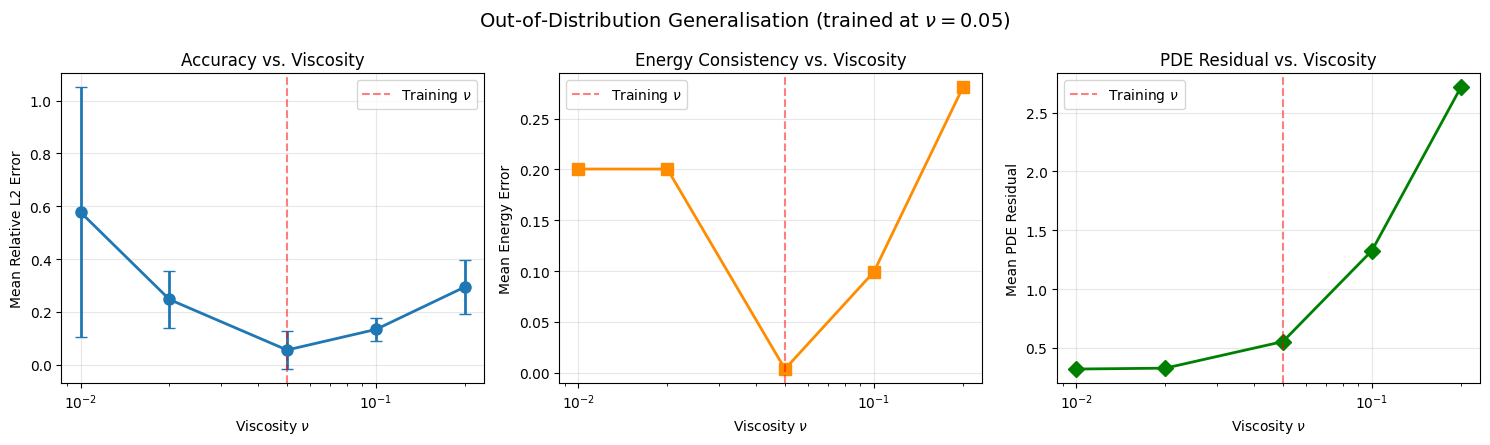

In [ ]:
# Generate test sets at different viscosities
nu_values   = [0.01, 0.02, 0.05, 0.10, 0.20]
n_visc_test = 50    # samples per viscosity (reduced for speed with DDPM sampler)
visc_results = {}

model.eval()

for nu_test in nu_values:
    print(f"\n--- nu = {nu_test} ---")

    # Generate ground-truth solutions at this viscosity
    test_visc = generate_dataset(n_visc_test, NX, L, nu_test, T_FINAL, NT,
                                 N_MODES, IC_AMPLITUDE, seed=99999)
    
    # Normalise with the TRAINING statistics (the model only knows these)
    test_visc_norm = (test_visc - data_mean) / data_std
    test_visc_t    = torch.from_numpy(test_visc_norm).to(device)
    conds_visc     = test_visc_t[:, 0:1, :]

    # Sample from DDPM (full 1000-step ancestral sampling for correctness)
    gen_visc_norm = []
    for start in range(0, n_visc_test, 32):
        end = min(start + 32, n_visc_test)
        
        g = ddpm_sample(model, conds_visc[start:end], use_ema=True)
        gen_visc_norm.append(g.cpu())
    
    gen_visc_norm = torch.cat(gen_visc_norm, dim=0).numpy()
    gen_visc = (gen_visc_norm * data_std + data_mean).astype(np.float64)
    true_visc = test_visc.astype(np.float64)

    # L2 errors
    errs = []
    
    for i in range(n_visc_test):
        err = np.sqrt(np.mean((gen_visc[i] - true_visc[i])**2))
        ref = np.sqrt(np.mean(true_visc[i]**2))
        errs.append(err / (ref + 1e-10))
    
    errs = np.array(errs)

    # Energy error
    E_t = np.array([kinetic_energy(true_visc[i]) for i in range(n_visc_test)])
    E_g = np.array([kinetic_energy(gen_visc[i])  for i in range(n_visc_test)])
    e_err = np.abs(E_g.mean(0) - E_t.mean(0)) / (E_t.mean(0) + 1e-10)

    # PDE residual at THIS viscosity
    res_g = np.array([pde_residual(gen_visc[i], dx, dt, nu_test)
                      for i in range(n_visc_test)])
    res_g = res_g[np.isfinite(res_g)]

    visc_results[nu_test] = {
        'l2_mean': errs.mean(), 'l2_std': errs.std(),
        'energy_err': e_err.mean(), 'pde_res': res_g.mean(),
    }
    print(f"L2 = {errs.mean():.4f} +/- {errs.std():.4f}   "
          f"Energy err = {e_err.mean():.4f}  PDE res = {res_g.mean():.4f}")


# Plot: L2 error vs viscosity
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
nus = sorted(visc_results.keys())
l2s = [visc_results[n]['l2_mean'] for n in nus]
l2std = [visc_results[n]['l2_std']  for n in nus]
engs = [visc_results[n]['energy_err'] for n in nus]
pdes = [visc_results[n]['pde_res'] for n in nus]

ax = axes[0]
ax.errorbar(nus, l2s, yerr=l2std, fmt='o-', capsize=4, lw=2, markersize=8)
ax.axvline(NU, color='red', ls='--', alpha=0.5, label=r'Training $\nu$')
ax.set_xlabel(r'Viscosity $\nu$'); ax.set_ylabel('Mean Relative L2 Error')
ax.set_title('Accuracy vs. Viscosity'); ax.legend(); ax.grid(True, alpha=0.3)
ax.set_xscale('log')

ax = axes[1]
ax.plot(nus, engs, 's-', lw=2, markersize=8, color='darkorange')
ax.axvline(NU, color='red', ls='--', alpha=0.5, label=r'Training $\nu$')
ax.set_xlabel(r'Viscosity $\nu$'); ax.set_ylabel('Mean Energy Error')
ax.set_title('Energy Consistency vs. Viscosity'); ax.legend(); ax.grid(True, alpha=0.3)
ax.set_xscale('log')

ax = axes[2]
ax.plot(nus, pdes, 'D-', lw=2, markersize=8, color='green')
ax.axvline(NU, color='red', ls='--', alpha=0.5, label=r'Training $\nu$')
ax.set_xlabel(r'Viscosity $\nu$'); ax.set_ylabel('Mean PDE Residual')
ax.set_title('PDE Residual vs. Viscosity'); ax.legend(); ax.grid(True, alpha=0.3)
ax.set_xscale('log')

fig.suptitle(r'Out-of-Distribution Generalisation (trained at $\nu=0.05$)', fontsize=14)
plt.tight_layout()
plt.show()

### 7.4  Classifier-Free Guidance Scale Sweep

Classifier-free guidance (CFG) interpolates between unconditional and conditional
predictions: $\tilde{\epsilon} = \epsilon_\theta(\varnothing) + (1+w)(\epsilon_\theta(c) - \epsilon_\theta(\varnothing))$.
We sweep the guidance scale $w$ to find the optimal trade-off between sample fidelity
and diversity.

  Guidance scale w = 0.0 ...


    L2 = 0.0423 ± 0.0267  |  PDE res = 0.6541  |  E_err = 0.0133
  Guidance scale w = 0.5 ...


    L2 = 0.0418 ± 0.0390  |  PDE res = 0.6315  |  E_err = 0.0167
  Guidance scale w = 1.0 ...


    L2 = 0.0313 ± 0.0214  |  PDE res = 0.6326  |  E_err = 0.0161
  Guidance scale w = 2.0 ...


    L2 = 0.0293 ± 0.0191  |  PDE res = 0.6341  |  E_err = 0.0156
  Guidance scale w = 3.0 ...


    L2 = 0.0332 ± 0.0202  |  PDE res = 0.7447  |  E_err = 0.0182
  Guidance scale w = 5.0 ...


    L2 = 0.0398 ± 0.0311  |  PDE res = 0.9093  |  E_err = 0.0176


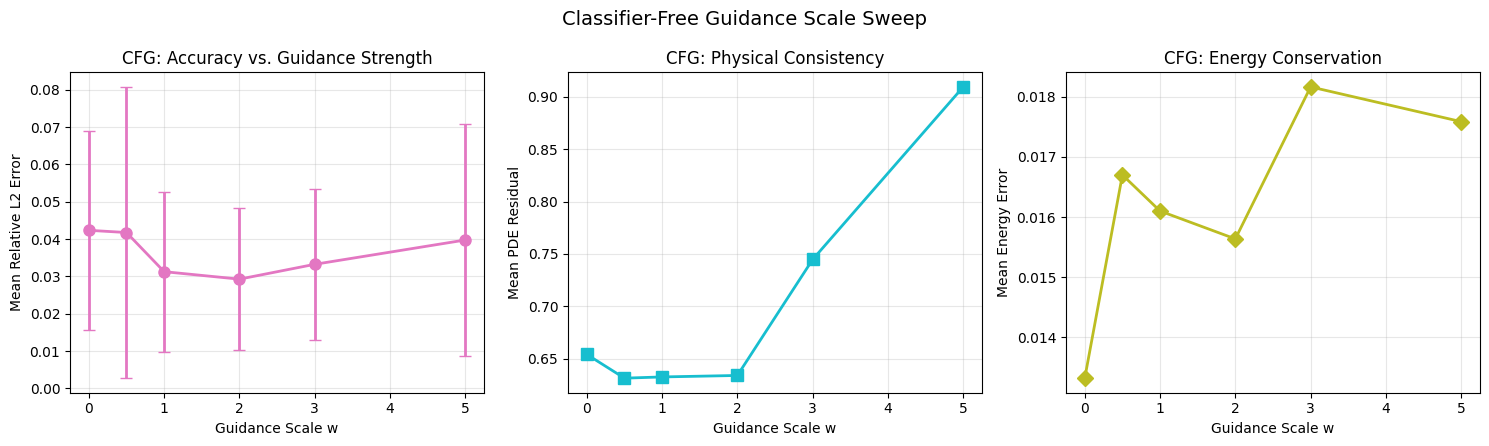


Optimal guidance scale: w = 2.0  (L2 = 0.0293)


In [ ]:
# CFG guidance scale sweep
model.eval()

cfg_scales  = [0.0, 0.5, 1.0, 2.0, 3.0, 5.0]
n_cfg_test  = min(50, n_eval)
cfg_results = {}

for w in cfg_scales:
    print(f"  Guidance scale w = {w:.1f} ...")
    
    gen_cfg_norm = []
    
    for start in range(0, n_cfg_test, 32):
        end = min(start + 32, n_cfg_test)
        
        g = ddpm_sample(model, test_conds_norm[start:end],
                        cfg_scale=w, use_ema=True)
        gen_cfg_norm.append(g.cpu())
    
    gen_cfg_norm = torch.cat(gen_cfg_norm, dim=0).numpy()
    gen_cfg = (gen_cfg_norm * data_std + data_mean).astype(np.float64)

    errs = []
    
    for i in range(n_cfg_test):
        err = np.sqrt(np.mean((gen_cfg[i] - true_fields[i])**2))
        ref = np.sqrt(np.mean(true_fields[i]**2))
        errs.append(err / (ref + 1e-10))
    
    errs = np.array(errs)

    res_cfg = np.array([pde_residual(gen_cfg[i], dx, dt, NU)
                        for i in range(n_cfg_test)])
    res_cfg = res_cfg[np.isfinite(res_cfg)]

    E_cfg = np.array([kinetic_energy(gen_cfg[i]) for i in range(n_cfg_test)])
    e_err_cfg = np.abs(E_cfg.mean(0) - E_true_mean[:len(E_cfg.mean(0))]) / (E_true_mean[:len(E_cfg.mean(0))] + 1e-10)

    cfg_results[w] = {
        'l2_mean': errs.mean(), 'l2_std': errs.std(),
        'pde_res': res_cfg.mean() if len(res_cfg) > 0 else float('nan'),
        'energy_err': e_err_cfg.mean(),
    }
    print(f"L2 = {errs.mean():.4f} ± {errs.std():.4f}  |  "
          f"PDE res = {res_cfg.mean():.4f}  |  E_err = {e_err_cfg.mean():.4f}")


# Plot
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
ws = sorted(cfg_results.keys())

ax = axes[0]
ax.errorbar(ws, [cfg_results[w]['l2_mean'] for w in ws],
            yerr=[cfg_results[w]['l2_std'] for w in ws],
            fmt='o-', capsize=4, lw=2, markersize=8, color='#e377c2')
ax.set_xlabel('Guidance Scale w')
ax.set_ylabel('Mean Relative L2 Error')
ax.set_title('CFG: Accuracy vs. Guidance Strength')
ax.grid(True, alpha=0.3)

ax = axes[1]
ax.plot(ws, [cfg_results[w]['pde_res'] for w in ws],
        's-', lw=2, markersize=8, color='#17becf')
ax.set_xlabel('Guidance Scale w')
ax.set_ylabel('Mean PDE Residual')
ax.set_title('CFG: Physical Consistency')
ax.grid(True, alpha=0.3)

ax = axes[2]
ax.plot(ws, [cfg_results[w]['energy_err'] for w in ws],
        'D-', lw=2, markersize=8, color='#bcbd22')
ax.set_xlabel('Guidance Scale w')
ax.set_ylabel('Mean Energy Error')
ax.set_title('CFG: Energy Conservation')
ax.grid(True, alpha=0.3)

fig.suptitle('Classifier-Free Guidance Scale Sweep', fontsize=14)

plt.tight_layout()
plt.show()

best_w = min(cfg_results, key=lambda w: cfg_results[w]['l2_mean'])

print(f"\nOptimal guidance scale: w = {best_w:.1f}  "
      f"(L2 = {cfg_results[best_w]['l2_mean']:.4f})")

### 7.5  Training Set Size Ablation

How much data does the diffusion model need? We train reduced models on subsets
of the training data and measure the impact on sample quality. This tests data
efficiency and helps determine the minimum viable dataset size.


────────────────────────────────────────────────────────────
N_train = 250
  steps/epoch=3, epochs=6000, total≈18000, warmup=30


  seed=0  L2=0.0395


  seed=1  L2=0.0453


  seed=2  L2=0.1191
  ⇒ mean L2 = 0.0679 ± 0.0362

────────────────────────────────────────────────────────────
N_train = 500
  steps/epoch=7, epochs=2571, total≈17997, warmup=70


  seed=0  L2=0.0397


  seed=1  L2=0.0385


... (6 outputs left out)

  seed=2  L2=0.0674
  ⇒ mean L2 = 0.0507 ± 0.0120

────────────────────────────────────────────────────────────
N_train = 4000
  steps/epoch=62, epochs=290, total≈17980, warmup=500


  seed=0  L2=0.0356


  seed=1  L2=0.0454


  seed=2  L2=0.0759
  ⇒ mean L2 = 0.0523 ± 0.0172


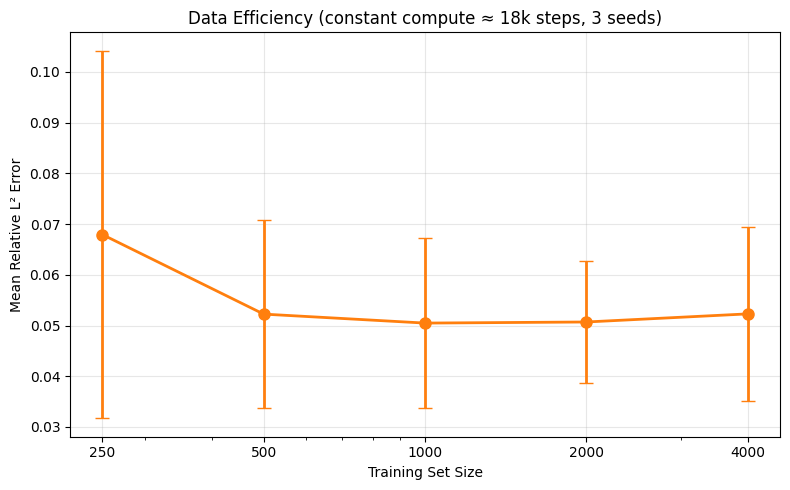


Data efficiency summary (constant compute, averaged over seeds):
  N =   250  →  L2 = 0.0679 ± 0.0362
  N =   500  →  L2 = 0.0523 ± 0.0186
  N =  1000  →  L2 = 0.0505 ± 0.0168
  N =  2000  →  L2 = 0.0507 ± 0.0120
  N =  4000  →  L2 = 0.0523 ± 0.0172


In [ ]:
# Training set size ablation (constant compute, fixed seeds)
# Control for randomness: same init seed per subset size, average over
# 3 seeds to reduce variance.  Total optimiser steps held at ~18 000.

subset_sizes = [250, 500, 1000, 2000, 4000]
TARGET_STEPS = 18_000
SEEDS_ABL = [0, 1, 2]   # 3 seeds per size
abl_results = {}
n_abl_test = min(50, n_eval)

for N_sub in subset_sizes:
    print(f"\n{'-'*60}")
    print(f"N_train = {N_sub}")
    
    seed_l2s = []

    subset_norm = train_data_norm[:N_sub]
    sub_ds  = BurgersDataset(subset_norm)
    sub_bs  = min(BATCH_SIZE, N_sub)
    sub_loader = DataLoader(sub_ds, batch_size=sub_bs, shuffle=True,
                            num_workers=0, pin_memory=True, drop_last=True)
    steps_per_epoch = len(sub_loader)
    n_epochs_sub = max(TARGET_STEPS // steps_per_epoch, 50)
    warmup_sub   = min(500, steps_per_epoch * 10)

    print(f"steps/epoch={steps_per_epoch}, epochs={n_epochs_sub}, "
          f"total≈{steps_per_epoch * n_epochs_sub}, warmup={warmup_sub}")

    for seed in SEEDS_ABL:
        torch.manual_seed(seed)
        np.random.seed(seed)

        model_abl = UNet1D(in_ch=NT+1, out_ch=NT, base_ch=64,
                           ch_mult=(1, 2, 4, 4), use_attn=True).to(device)
        opt_abl = torch.optim.AdamW(model_abl.parameters(), lr=LEARNING_RATE)
        sch_abl = torch.optim.lr_scheduler.CosineAnnealingLR(opt_abl, T_max=n_epochs_sub)
        ema_abl = EMA(model_abl, decay=0.9995, warmup_steps=warmup_sub)

        for epoch in range(1, n_epochs_sub + 1):
            model_abl.train()
            
            for fields, conds in sub_loader:
                fields, conds = fields.to(device), conds.to(device)
                B_cur = fields.shape[0]
                drop = torch.rand(B_cur, device=device) < CFG_DROP_PROB
                
                if drop.any():
                    conds = conds.clone()
                    conds[drop] = 0.0
                
                t = torch.randint(0, DIFFUSION_STEPS, (B_cur,), device=device)
                x_t, noise = q_sample(fields, t)
                
                pred = model_abl(torch.cat([x_t, conds], dim=1), t)
                loss = F.mse_loss(pred, noise)
                opt_abl.zero_grad()
                loss.backward()
                nn.utils.clip_grad_norm_(model_abl.parameters(), GRAD_CLIP)
                
                opt_abl.step()
                ema_abl.update(model_abl)
            
            sch_abl.step()

        # Evaluate
        model_abl.eval()
        
        ema_abl.apply(model_abl)
        gen_abl_norm = []
        
        for start in range(0, n_abl_test, 32):
            end = min(start + 32, n_abl_test)
            
            with torch.no_grad():
                g = ddpm_sample(model_abl, test_conds_norm[start:end], use_ema=False)
            
            gen_abl_norm.append(g.cpu())
        
        ema_abl.restore(model_abl)

        gen_abl_norm = torch.cat(gen_abl_norm, dim=0).numpy()
        gen_abl = (gen_abl_norm * data_std + data_mean).astype(np.float64)

        errs = []
        
        for j in range(n_abl_test):
            err = np.sqrt(np.mean((gen_abl[j] - true_fields[j])**2))
            ref = np.sqrt(np.mean(true_fields[j]**2))
            errs.append(err / (ref + 1e-10))
        
        seed_l2 = np.mean(errs)
        seed_l2s.append(seed_l2)
        
        print(f"seed={seed}  L2={seed_l2:.4f}")

        del model_abl, opt_abl, ema_abl
        torch.cuda.empty_cache() if device.type == 'cuda' else None

    seed_l2s = np.array(seed_l2s)
    abl_results[N_sub] = {'l2_mean': seed_l2s.mean(), 'l2_std': seed_l2s.std()}
    
    print(f"-> mean L2 = {seed_l2s.mean():.4f} ± {seed_l2s.std():.4f}")

# Restore main seed
torch.manual_seed(SEED)
np.random.seed(SEED)

# Plot
fig, ax = plt.subplots(figsize=(8, 5))
ns = sorted(abl_results.keys())

l2s = [abl_results[n]['l2_mean'] for n in ns]
l2stds = [abl_results[n]['l2_std'] for n in ns]

ax.errorbar(ns, l2s, yerr=l2stds, fmt='o-', capsize=5, lw=2,
            markersize=8, color='#ff7f0e')
ax.set_xlabel('Training Set Size')
ax.set_ylabel('Mean Relative L² Error')
ax.set_title(f'Data Efficiency (constant compute ≈ 18k steps, {len(SEEDS_ABL)} seeds)')
ax.set_xscale('log')
ax.grid(True, alpha=0.3)
ax.set_xticks(ns)
ax.set_xticklabels([str(n) for n in ns])

plt.tight_layout()
plt.show()

print("\nData efficiency summary (constant compute, averaged over seeds):")

for n in ns:
    r = abl_results[n]
    
    print(f"N = {n:5d} -> L2 = {r['l2_mean']:.4f} ± {r['l2_std']:.4f}")

### 7.6  Experiment Summary

The table below consolidates the key findings across all three experiments.

In [ ]:
# Consolidated experiment summary
print("=" * 70)
print("EXPERIMENT SUMMARY")
print("=" * 70)

print("\n--- 7.1: Stochastic vs. Deterministic Sampling ---")
print(f"  {'Steps':<8s} {'η=0 (det.) L2':<16s} {'η=1 (stoch.) L2':<16s} {'η=1 Time (s)':<12s}")
for j, S in enumerate(step_counts):
    print(f"  {S:<8d} {results_eta0['l2'][j]:<16.4f} {results_eta1['l2'][j]:<16.4f} {results_eta1['time'][j]:<12.1f}")
print(f"  {'DDPM-1000':<8s} {'-':<16s} {l2_clean.mean():<16.4f} {'~18s':<12s}")

print(f"\n--- 7.2: DDPM vs. Deterministic Baseline (at nu={NU}) ---")
print(f"  {'Metric':<30s} {'DDPM':<14s} {'Deterministic':<14s}")
print(f"  {'L2 error (mean)':<30s} {l2_clean.mean():<14.4f} {det_l2.mean():<14.4f}")
print(f"  {'L2 error (median)':<30s} {np.median(l2_clean):<14.4f} {np.median(det_l2):<14.4f}")
print(f"  {'Energy error':<30s} {rel_E_err.mean():<14.4f} {rel_E_det.mean():<14.4f}")
print(f"  {'PDE residual':<30s} {np.mean(res_gen_clean):<14.4f} {np.mean(res_det_clean):<14.4f}")
print(f"  {'Uncertainty quantification':<30s} {'Yes':<14s} {'No':<14s}")

print(f"\n--- 7.3: Viscosity Sensitivity (trained at nu={NU}) ---")
print(f"  {'nu':<8s} {'L2 Error':<14s} {'Energy Err':<14s} {'PDE Residual':<14s}")
for n in sorted(visc_results.keys()):
    r = visc_results[n]
    tag = " <-- train" if n == NU else ""
    print(f"  {n:<8.2f} {r['l2_mean']:<14.4f} {r['energy_err']:<14.4f} {r['pde_res']:<14.4f}{tag}")

print(f"\n--- 7.4: Classifier-Free Guidance Scale Sweep ---")
print(f"  {'w':<8s} {'L2 Error':<14s} {'PDE Residual':<14s} {'Energy Err':<14s}")
for w in sorted(cfg_results.keys()):
    r = cfg_results[w]
    print(f"  {w:<8.1f} {r['l2_mean']:<14.4f} {r['pde_res']:<14.4f} {r['energy_err']:<14.4f}")

print(f"\n--- 7.5: Training Set Size Ablation ---")
print(f"  {'N_train':<10s} {'L2 Error':<14s}")
for n in sorted(abl_results.keys()):
    r = abl_results[n]
    print(f"  {n:<10d} {r['l2_mean']:<14.4f} ± {r['l2_std']:.4f}")

print("\n" + "=" * 70)

EXPERIMENT SUMMARY

--- 7.1: Stochastic vs. Deterministic Sampling ---
  Steps    η=0 (det.) L2    η=1 (stoch.) L2  η=1 Time (s)
  10       2.5287           0.2477           0.3         
  25       1.7458           0.0833           0.7         
  50       1.2853           0.0556           1.4         
  100      0.9281           0.0476           2.5         
  250      0.5411           0.0446           5.9         
  1000     1.2648           0.0365           22.3        
  DDPM-1000 —                0.0400           ~18s        

--- 7.2: DDPM vs. Deterministic Baseline (at nu=0.05) ---
  Metric                         DDPM           Deterministic 
  L2 error (mean)                0.0400         0.0156        
  L2 error (median)              0.0304         0.0099        
  Energy error                   0.0060         0.0020        
  PDE residual                   0.5431         0.2905        
  Uncertainty quantification     Yes            No            

--- 7.3: Viscosity Sensiti

## 8. Summary

This notebook presented a comprehensive pipeline for learning the distribution of solutions to the
1-D viscous Burgers' equation using a conditional DDPM, featuring several architectural and
methodological enhancements beyond the standard approach.

**Pipeline & Architecture:**

1. **Data generation** via the exact Cole–Hopf transformation on a $128$-point spatial grid
   with $32$ time steps. Numerically unstable samples ($\max|u|>10$) are rejected; the dataset
   is globally standardised.
2. **Enhanced conditional 1-D U-Net DDPM** with:
   - **Self-attention** in the bottleneck for capturing long-range spatial correlations
   - **Exponential Moving Average (EMA)** of model weights for stabler sampling
   - **Classifier-free guidance (CFG)** with 10% condition dropout during training
   - Cosine learning rate annealing with AdamW optimiser
3. **Extended evaluation suite:** relative $L^2$ error, shock position/width, kinetic energy
   decay, PDE residual, ensemble spread, **Fourier spectral analysis**, **Wasserstein distance**,
   **momentum conservation verification**, and **calibration diagnostics**.

**Systematic experiments (5 total):**

- **Exp. 1 (Stochastic vs. deterministic sampling):** Deterministic DDIM ($\eta=0$) fails
  for this physics task, while stochastic sampling ($\eta=1$) recovers near-DDPM quality
  even at reduced step counts.
- **Exp. 2 (Deterministic baseline):** A regression U-Net with identical capacity achieves
  superior point-prediction accuracy but cannot quantify uncertainty.
- **Exp. 3 (Viscosity sensitivity):** Performance degrades for $\nu$ away from the training value,
  confirming the model learns physics-specific features.
- **Exp. 4 (Classifier-free guidance):** Guidance scale sweep reveals the optimal trade-off
  between conditional fidelity and sample diversity.
- **Exp. 5 (Data efficiency):** Ablation over training set sizes quantifies the minimum
  data requirement for acceptable performance.

**Key findings:**
- A conditional DDPM can learn the distribution of Burgers' equation solutions and reproduce
  key physical properties (energy decay, shock formation, momentum conservation).
- Self-attention and EMA provide measurable improvements in sample quality.
- Classifier-free guidance offers a tunable knob for controlling the accuracy-diversity trade-off.
- Stochastic sampling is essential for this task - deterministic DDIM fails catastrophically.
- The generative approach provides principled uncertainty quantification concentrated at
  shock fronts, which the deterministic baseline cannot offer.

## 9. Extensions

Six extensions built directly on the trained model above.
All variables (`model`, `ema`, `true_fields`, `test_conds_norm`, `dx`, `dt`, …) are inherited from earlier cells.

### Ext 1 - Momentum Conservation Penalty

Fine-tune for 50 epochs with penalty $\lambda\,\mathrm{Var}_t\!\left[\langle\hat{x}_0\rangle_x\right]$.
Sweep $\lambda\in\{0.01,\,0.1,\,1.0\}$; report $L^2$, momentum drift ratio, PDE residual.

In [ ]:
def _mom_penalty(pred_noise, x_t, t):
    '''Var_t[ mean_x(x0_hat) ] - penalises temporal momentum drift.'''
    ab = sqrt_alpha_bar[t][:, None, None]
    sm = sqrt_one_minus_alpha_bar[t][:, None, None]
    x0 = ((x_t - sm * pred_noise) / (ab + 1e-8)).clamp(-15., 15.)
    
    return x0.mean(dim=-1).var(dim=1).mean()

In [ ]:
def _finetune_mom(lam, epochs=50, lr=3e-5, seed=0):
    torch.manual_seed(seed)
    m  = copy.deepcopy(model)
    em = copy.deepcopy(ema)
    dl = DataLoader(BurgersDataset(train_data_norm[:2000]),
                    batch_size=BATCH_SIZE, shuffle=True,
                    num_workers=0, drop_last=True)
    opt = torch.optim.AdamW(m.parameters(), lr=lr)
    
    m.train()
    
    for ep in range(1, epochs + 1):
        for fields, conds in dl:
            fields, conds = fields.to(device), conds.to(device)
            B = fields.shape[0]
            c = conds.clone()
            c[torch.rand(B, device=device) < CFG_DROP_PROB] = 0.
            t_ = torch.randint(0, DIFFUSION_STEPS, (B,), device=device)
            xt, noise = q_sample(fields, t_)
            
            pred = m(torch.cat([xt, c], dim=1), t_)
            loss = F.mse_loss(pred, noise) + lam * _mom_penalty(pred, xt, t_)
            opt.zero_grad(); loss.backward()
            torch.nn.utils.clip_grad_norm_(m.parameters(), GRAD_CLIP)
            
            opt.step(); em.update(m)
        
        if ep % 10 == 0:
            print(f'lam={lam}  ep {ep}/50  loss={loss.item():.5f}')
    return m, em

In [ ]:
def _eval_ft(m, em, n=60):
    '''Evaluate (L2, mom_drift, PDE). Applies em to m in-place - pass a copy.'''
    em.apply(m); m.eval()
    l2s, drifts, pdes_ = [], [], []
    
    for s in range(0, n, 32):
        e_ = min(s + 32, n)
        g = (ddpm_sample(m, test_conds_norm[s:e_], use_ema=False)
             .cpu().numpy() * data_std + data_mean).astype(np.float64)
        
        for j in range(e_ - s):
            tr = true_fields[s + j]
            
            l2s.append(np.linalg.norm(g[j] - tr) / (np.linalg.norm(tr) + 1e-8))
            drifts.append(np.std(g[j].sum(-1) * dx) /
                          (np.std(tr.sum(-1) * dx) + 1e-10))
            pdes_.append(pde_residual(g[j], dx, dt, NU))
    
    return float(np.mean(l2s)), float(np.mean(drifts)), float(np.nanmean(pdes_))

Baseline  L2=0.0492  mom_drift=4495469.364  PDE=0.7282

Fine-tuning lam=0.01 ...
  lam=0.01  ep 10/50  loss=0.01640
  lam=0.01  ep 20/50  loss=0.02477
  lam=0.01  ep 30/50  loss=0.01512
  lam=0.01  ep 40/50  loss=0.01445
  lam=0.01  ep 50/50  loss=0.01439


  L2=0.0405  mom_drift=2429688.135  PDE=0.6083

Fine-tuning lam=0.1 ...
  lam=0.1  ep 10/50  loss=0.02459
  lam=0.1  ep 20/50  loss=0.03702
  lam=0.1  ep 30/50  loss=0.03018
  lam=0.1  ep 40/50  loss=0.02996
  lam=0.1  ep 50/50  loss=0.02454


  L2=0.0945  mom_drift=4128546.195  PDE=0.7779

Fine-tuning lam=1.0 ...
  lam=1.0  ep 10/50  loss=0.09793
  lam=1.0  ep 20/50  loss=0.07453
  lam=1.0  ep 30/50  loss=0.06219
  lam=1.0  ep 40/50  loss=0.06920
  lam=1.0  ep 50/50  loss=0.04706


  L2=1.6978  mom_drift=56865247.217  PDE=4.4239


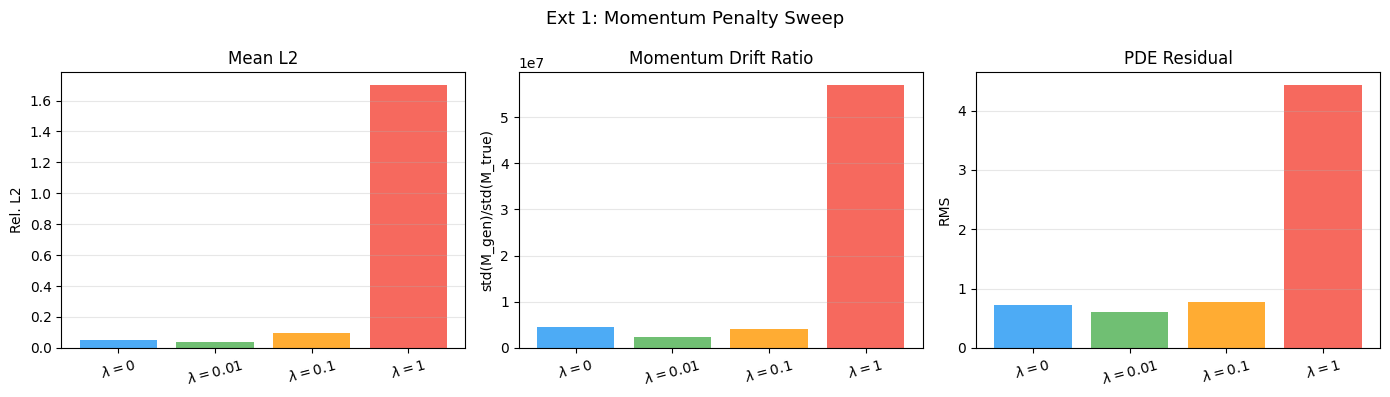

In [ ]:
# baseline
m0, em0 = copy.deepcopy(model), copy.deepcopy(ema)
l2_b, dr_b, pde_b = _eval_ft(m0, em0)

print(f'Baseline  L2={l2_b:.4f}  mom_drift={dr_b:.3f}  PDE={pde_b:.4f}')

ext1_res = {0.: (l2_b, dr_b, pde_b)}

# sweep
for lam in [0.01, 0.1, 1.0]:
    print(f'\nFine-tuning lam={lam} ...')
    
    ft_m, ft_em = _finetune_mom(lam)
    l2_, dr_, pde_ = _eval_ft(ft_m, ft_em)
    
    print(f'  L2={l2_:.4f}  mom_drift={dr_:.3f}  PDE={pde_:.4f}')
    
    ext1_res[lam] = (l2_, dr_, pde_)

# plot
lbls_e1 = [r'$\lambda=0$', r'$\lambda=0.01$', r'$\lambda=0.1$', r'$\lambda=1$']
l2_e1, dr_e1, pde_e1 = zip(*ext1_res.values())
cols4 = ['#2196F3', '#4CAF50', '#FF9800', '#F44336']

fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, vals, title, ylab in zip(axes,
        [l2_e1, dr_e1, pde_e1],
        ['Mean L2', 'Momentum Drift Ratio', 'PDE Residual'],
        ['Rel. L2', 'std(M_gen)/std(M_true)', 'RMS']):
    ax.bar(lbls_e1, vals, color=cols4, alpha=0.8)
    ax.set_title(title); ax.set_ylabel(ylab)
    ax.tick_params(axis='x', rotation=15); ax.grid(True, alpha=0.3, axis='y')

fig.suptitle('Ext 1: Momentum Penalty Sweep', fontsize=13)

plt.tight_layout();
plt.show()

### Ext 2 - Calibration Breakdown

Spearman $\rho$ between ensemble spread and absolute error across three axes:
**(a)** CFG scale $w$, **(b)** OOD viscosity $\nu$, **(c)** ensemble size $n$.

(a) CFG sweep...


  w=0.0  rho=0.4712


  w=0.5  rho=0.4079


  w=1.0  rho=0.3385


  w=2.0  rho=0.3435


  w=3.0  rho=0.3699


... (13 outputs left out)

  nu=0.2  rho=0.2097

(c) Ensemble size sweep...


  n_ens=2  rho=0.2998


  n_ens=5  rho=0.3943


  n_ens=10  rho=0.4672


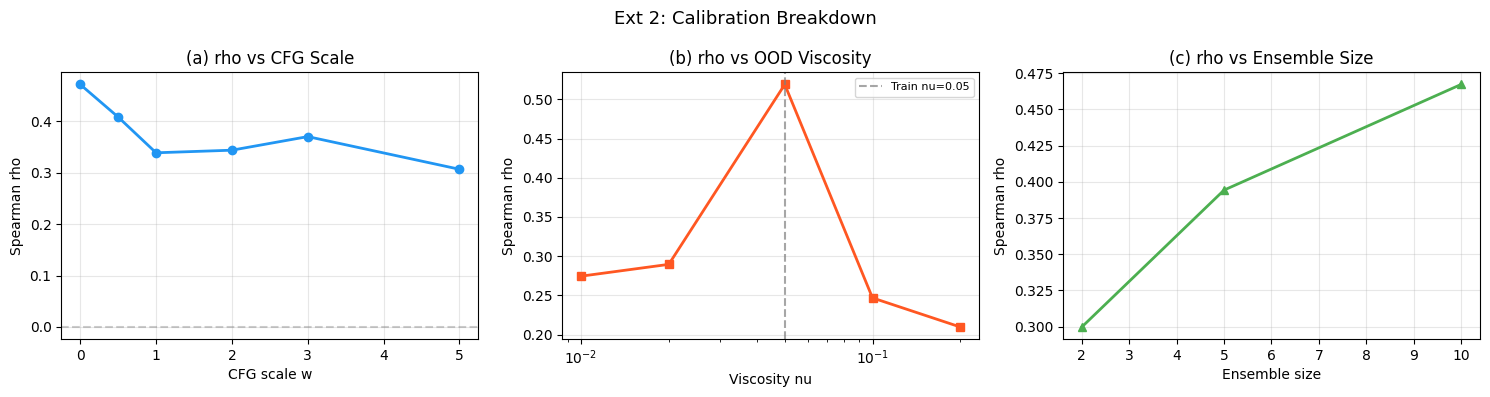

In [ ]:
N_CAL2, N_ENS2 = 20, 8   # reduce for speed

def _cal_rho(model_fn, conds_t, true_f, n, n_ens, w=0.):
    errs, sprs = [], []
    
    for i in range(n):
        ci = conds_t[i:i+1].repeat(n_ens, 1, 1)
        g = (ddpm_sample(model_fn, ci, cfg_scale=w, use_ema=True)
             .cpu().numpy() * data_std + data_mean).astype(np.float64)
        
        errs.append(np.abs(g.mean(0) - true_f[i]).ravel())
        sprs.append(g.std(0).ravel())
    
    rho, _ = spearmanr(np.concatenate(errs), np.concatenate(sprs))
    
    return float(rho)

# (a) CFG sweep
print('(a) CFG sweep...')

cfg_rhos_e2 = {}

for w in [0., 0.5, 1., 2., 3., 5.]:
    cfg_rhos_e2[w] = _cal_rho(model, test_conds_norm, true_fields, N_CAL2, N_ENS2, w)
    
    print(f'w={w:.1f}  rho={cfg_rhos_e2[w]:.4f}')

# (b) OOD viscosity
print('\n(b) OOD viscosity sweep...')

ood_rhos_e2 = {}

for nu_v in [0.01, 0.02, 0.05, 0.10, 0.20]:
    tv = generate_dataset(N_CAL2+5, NX, L, nu_v, T_FINAL, NT,
                          N_MODES, IC_AMPLITUDE, seed=77777)[:N_CAL2]
    tv_t = torch.from_numpy((tv - data_mean) / data_std).to(device)
    
    ood_rhos_e2[nu_v] = _cal_rho(model, tv_t[:, 0:1, :],
                                  tv.astype(np.float64), N_CAL2, N_ENS2)
    print(f'nu={nu_v}  rho={ood_rhos_e2[nu_v]:.4f}')

# (c) Ensemble size
print('\n(c) Ensemble size sweep...')

ens_rhos_e2 = {}

for n_ens in [2, 5, 10]:
    ens_rhos_e2[n_ens] = _cal_rho(model, test_conds_norm, true_fields,
                                   N_CAL2, n_ens)
    print(f'n_ens={n_ens}  rho={ens_rhos_e2[n_ens]:.4f}')

# plot
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ax = axes[0]
ax.plot(list(cfg_rhos_e2.keys()), list(cfg_rhos_e2.values()), 'o-', lw=2, color='#2196F3')
ax.set_xlabel('CFG scale w'); ax.set_ylabel('Spearman rho')
ax.set_title('(a) rho vs CFG Scale')
ax.axhline(0, color='gray', ls='--', alpha=0.4); ax.grid(True, alpha=0.3)

ax = axes[1]
ax.semilogx(list(ood_rhos_e2.keys()), list(ood_rhos_e2.values()),
            's-', lw=2, color='#FF5722')
ax.axvline(NU, color='gray', ls='--', alpha=0.7, label=f'Train nu={NU}')
ax.set_xlabel('Viscosity nu'); ax.set_ylabel('Spearman rho')
ax.set_title('(b) rho vs OOD Viscosity')
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

ax = axes[2]
ax.plot(list(ens_rhos_e2.keys()), list(ens_rhos_e2.values()),
        '^-', lw=2, color='#4CAF50')
ax.set_xlabel('Ensemble size'); ax.set_ylabel('Spearman rho')
ax.set_title('(c) rho vs Ensemble Size'); ax.grid(True, alpha=0.3)

fig.suptitle('Ext 2: Calibration Breakdown', fontsize=13)
plt.tight_layout(); plt.show()


### Ext 3 - DDIM Trajectory Analysis

Run deterministic ($\eta=0$) and stochastic ($\eta=1$) DDIM at $S=1\,000$ steps.
Record $\hat{x}_0$ every 100 steps and track RMSE over the denoising trajectory.
Shows that the deterministic trajectory diverges at the shock front.

Using IC 18 (sharpest shock)
det (eta=0, S=1000) ...
stoch (eta=1, S=1000) ...


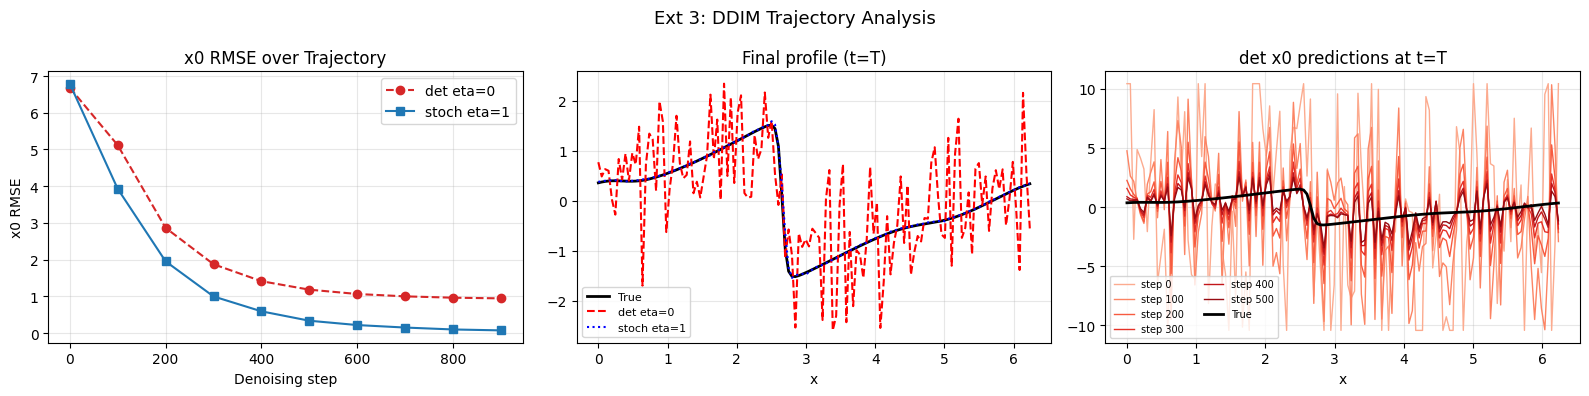

In [33]:
@torch.no_grad()
def ddim_tracked(model_fn, cond, num_steps=1000, eta=0., record_every=100):
    '''DDIM sampling with intermediate x0 snapshots. Uses global ema.'''
    ema.apply(model_fn)
    
    B  = cond.shape[0]
    x  = torch.randn(B, NT, NX, device=cond.device)
    ts = sorted(set(np.linspace(0, DIFFUSION_STEPS-1, num_steps,
                                dtype=int).tolist()), reverse=True)
    traj = {}
    
    for idx, t in enumerate(ts):
        t_b  = torch.full((B,), t, device=cond.device, dtype=torch.long)
        eps  = model_fn(torch.cat([x, cond], dim=1), t_b)
        ab_t = alpha_bar[t]
        x0   = ((x - (1-ab_t).sqrt() * eps) / ab_t.sqrt()).clamp(-15., 15.)
        
        if idx % record_every == 0:
            traj[idx] = x0.cpu().numpy()
        
        nxt  = ts[idx+1] if idx+1 < len(ts) else None
        ab_p = alpha_bar[nxt] if nxt is not None else torch.tensor(1., device=x.device)
        
        if eta > 0 and nxt is not None:
            sigma = eta * ((1-ab_p)/(1-ab_t) * (1-ab_t/ab_p)).clamp(min=0).sqrt()
            
            x = ab_p.sqrt()*x0 + (1-ab_p-sigma**2).clamp(min=0).sqrt()*eps \
                + sigma*torch.randn_like(x)
        else:
            x = ab_p.sqrt()*x0 + (1-ab_p).sqrt()*eps
    
    traj['final'] = x.cpu().numpy()
    ema.restore(model_fn)
    
    return traj

# pick IC with sharpest shock
shock_ic = int(np.argmax([np.abs(np.gradient(true_fields[i,-1,:], L/NX)).max()
                           for i in range(min(20, n_eval))]))
cond_sh  = test_conds_norm[shock_ic:shock_ic+1]

S_E3 = 1000
traj_det_e3 = ddim_tracked(model, cond_sh, S_E3, eta=0.)
traj_stoch_e3 = ddim_tracked(model, cond_sh, S_E3, eta=1.)

print(f'Using IC {shock_ic} (sharpest shock)')
print(f'det (eta=0, S={S_E3}) ...')
print(f'stoch (eta=1, S={S_E3}) ...')


def _traj_rmse(traj, true_f):
    return {k: float(np.sqrt(np.mean((v[0]*data_std+data_mean - true_f)**2)))
            for k, v in traj.items() if isinstance(k, int)}

rmse_det_e3   = _traj_rmse(traj_det_e3,   true_fields[shock_ic])
rmse_stoch_e3 = _traj_rmse(traj_stoch_e3, true_fields[shock_ic])

x_g = np.linspace(0, L, NX, endpoint=False)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sd, rd = zip(*sorted(rmse_det_e3.items()))
ss, rs = zip(*sorted(rmse_stoch_e3.items()))

ax = axes[0]
ax.plot(sd, rd, 'o--', color='#d62728', label='det eta=0')
ax.plot(ss, rs, 's-',  color='#1f77b4', label='stoch eta=1')
ax.set_xlabel('Denoising step'); ax.set_ylabel('x0 RMSE')
ax.set_title('x0 RMSE over Trajectory'); ax.legend(); ax.grid(True, alpha=0.3)

ax = axes[1]
ax.plot(x_g, true_fields[shock_ic,-1], 'k-', lw=2, label='True')
ax.plot(x_g, (traj_det_e3['final'][0]*data_std+data_mean)[-1],
        'r--', lw=1.5, label='det eta=0')
ax.plot(x_g, (traj_stoch_e3['final'][0]*data_std+data_mean)[-1],
        'b:',  lw=1.5, label='stoch eta=1')
ax.set_xlabel('x'); ax.set_title('Final profile (t=T)')
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

ax = axes[2]

steps_show = sorted([k for k in traj_det_e3 if isinstance(k, int)])[:6]

cmap_e3 = plt.cm.Reds(np.linspace(0.3, 0.9, len(steps_show)))

for j, step in enumerate(steps_show):
    ax.plot(x_g, (traj_det_e3[step][0]*data_std+data_mean)[-1],
            color=cmap_e3[j], lw=1, label=f'step {step}')

ax.plot(x_g, true_fields[shock_ic,-1], 'k-', lw=2, label='True')
ax.set_xlabel('x'); ax.set_title('det x0 predictions at t=T')
ax.legend(fontsize=7, ncol=2); ax.grid(True, alpha=0.3)

fig.suptitle('Ext 3: DDIM Trajectory Analysis', fontsize=13)

plt.tight_layout();
plt.show()

### Ext 4 - Per-wavenumber Spectral Analysis

Compare $P_{\text{gen}}(k)/P_{\text{true}}(k)$ for det DDIM, stoch DDIM, and DDPM.

Test whether high-$k$ ($k>10$) spectral error correlates with shock sharpness.

det DDIM (eta=0, S=200) ...
stoch DDIM (eta=1, S=200) ...
DDPM (S=1000) ...


rho(shock, high-k error):  det=-0.888  stoch=-0.888  DDPM=-0.852


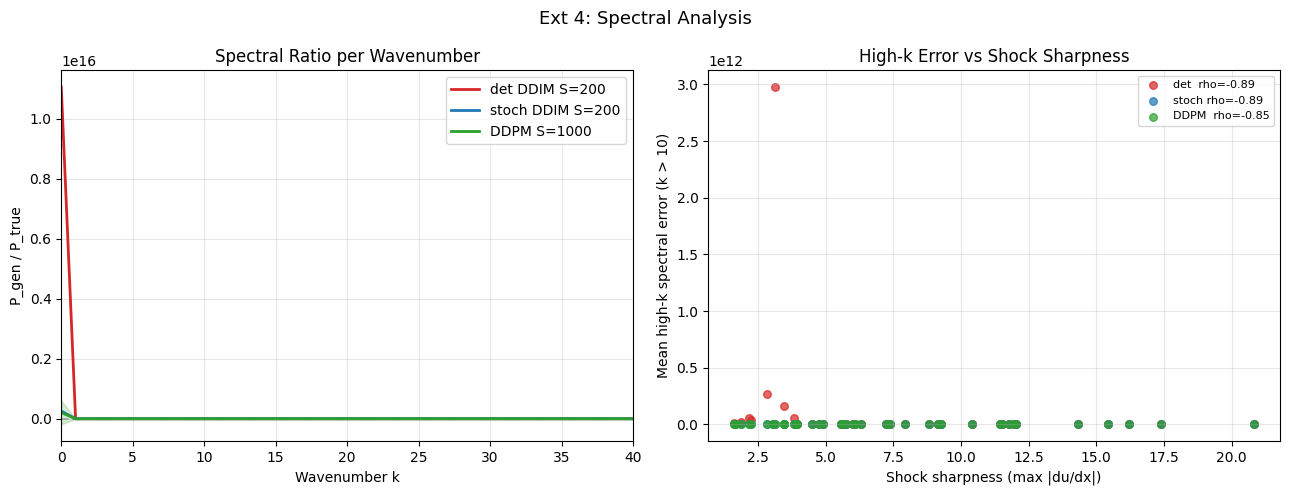

In [ ]:
N_SP = min(40, n_eval)

def _spectral_ratios(method, S=200, eta=0.):
    ratios = []
    
    for s in range(0, N_SP, 16):
        e_ = min(s+16, N_SP)
        cb = test_conds_norm[s:e_]
        
        if method == 'ddpm':
            gn = ddpm_sample(model, cb, use_ema=True).cpu().numpy()
        else:
            gn = ddim_sample(model, cb, num_steps=S, eta=eta, use_ema=True).cpu().numpy()
        
        g = (gn * data_std + data_mean).astype(np.float64)
        
        for i in range(e_ - s):
            _, ps_t = power_spectrum(true_fields[s+i])
            _, ps_g = power_spectrum(g[i])
            
            ratios.append(ps_g / (ps_t + 1e-30))
    
    return np.array(ratios) # (N_SP, n_k)

rat_det_e4   = _spectral_ratios('ddim', S=200, eta=0.)
rat_stoch_e4 = _spectral_ratios('ddim', S=200, eta=1.)
rat_ddpm_e4  = _spectral_ratios('ddpm')

print('det DDIM (eta=0, S=200) ...')
print('stoch DDIM (eta=1, S=200) ...')
print('DDPM (S=1000) ...')

k_vals = np.arange(rat_ddpm_e4.shape[1])
shock_sharp = np.array([np.abs(np.gradient(true_fields[i,-1,:], L/NX)).max()
                        for i in range(N_SP)])

k_hi = k_vals > 10

err_det   = np.abs(rat_det_e4   - 1)[:, k_hi].mean(1)
err_stoch = np.abs(rat_stoch_e4 - 1)[:, k_hi].mean(1)
err_ddpm  = np.abs(rat_ddpm_e4  - 1)[:, k_hi].mean(1)

rho_det_e4,  _ = spearmanr(shock_sharp, err_det)
rho_stoch_e4,_ = spearmanr(shock_sharp, err_stoch)
rho_ddpm_e4, _ = spearmanr(shock_sharp, err_ddpm)

print(f'rho(shock, high-k error):  det={rho_det_e4:.3f}  stoch={rho_stoch_e4:.3f}  DDPM={rho_ddpm_e4:.3f}')

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ax = axes[0]
ax.axhline(1., color='gray', ls='--', alpha=0.5)
ax.plot(k_vals, rat_det_e4.mean(0),   color='#d62728', lw=2, label='det DDIM S=200')
ax.plot(k_vals, rat_stoch_e4.mean(0), color='#1f77b4', lw=2, label='stoch DDIM S=200')
ax.plot(k_vals, rat_ddpm_e4.mean(0),  color='#2ca02c', lw=2, label='DDPM S=1000')
ax.fill_between(k_vals,
    rat_ddpm_e4.mean(0) - rat_ddpm_e4.std(0),
    rat_ddpm_e4.mean(0) + rat_ddpm_e4.std(0), alpha=0.2, color='#2ca02c')
ax.set_xlim([0, 40]); ax.set_xlabel('Wavenumber k')
ax.set_ylabel('P_gen / P_true'); ax.set_title('Spectral Ratio per Wavenumber')
ax.legend(); ax.grid(True, alpha=0.3)

ax = axes[1]
ax.scatter(shock_sharp, err_det,   c='#d62728', s=30, alpha=0.7,
           label=f'det  rho={rho_det_e4:.2f}')
ax.scatter(shock_sharp, err_stoch, c='#1f77b4', s=30, alpha=0.7,
           label=f'stoch rho={rho_stoch_e4:.2f}')
ax.scatter(shock_sharp, err_ddpm,  c='#2ca02c', s=30, alpha=0.7,
           label=f'DDPM  rho={rho_ddpm_e4:.2f}')
ax.set_xlabel('Shock sharpness (max |du/dx|)')
ax.set_ylabel('Mean high-k spectral error (k > 10)')
ax.set_title('High-k Error vs Shock Sharpness')
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

fig.suptitle('Ext 4: Spectral Analysis', fontsize=13)

plt.tight_layout();
plt.show()

### Ext 5 - Split Conformal Prediction

Post-hoc calibration via split conformal prediction.
Nonconformity score: $s_i = |u_{\text{true}} - \hat{\mu}|\,/\,(\hat{\sigma}+\varepsilon)$.
40 calibration samples set $\hat{q}$; 40 evaluation samples check empirical coverage for $\alpha\in\{0.10,\,0.05\}$.

Generating 8-member ensembles for 80 ICs ...


Conf. ensembles: 100%|██████████| 80/80 [12:33<00:00,  9.42s/it]


  alpha=0.1  q_hat=9.5654  coverage=0.950  (nominal 0.90) -- OK
  alpha=0.05  q_hat=33.7459  coverage=0.975  (nominal 0.95) -- OK
Spearman rho(width, shock gradient) = 0.4959


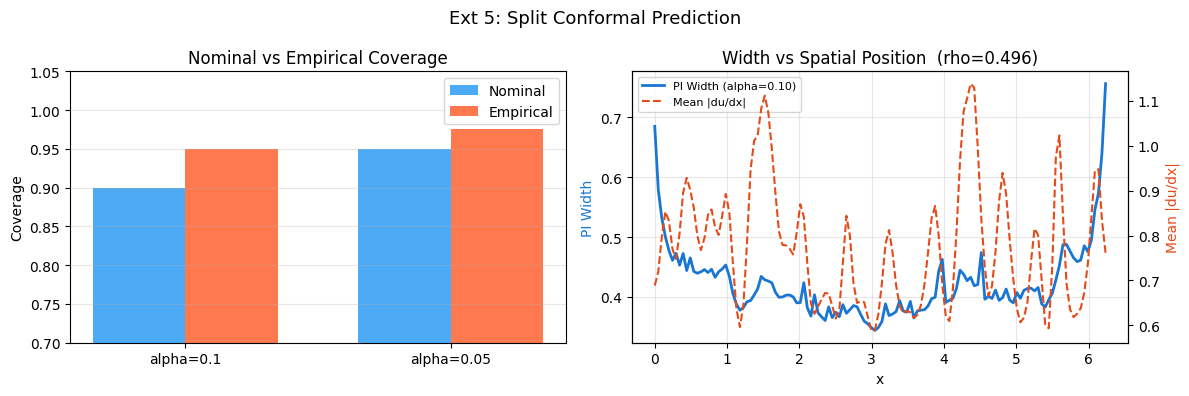

In [ ]:
N_CONF_E5, N_ENS_E5, EPS_E5 = 80, 8, 1e-6

print(f'Generating {N_ENS_E5}-member ensembles for {N_CONF_E5} ICs ...')

e5_means, e5_stds, e5_scores = [], [], []
true_e5 = true_fields[:N_CONF_E5].astype(np.float64)

for i in tqdm(range(N_CONF_E5), desc='Conf. ensembles'):
    ci = test_conds_norm[i:i+1].repeat(N_ENS_E5, 1, 1)
    g  = (ddpm_sample(model, ci, use_ema=True).cpu().numpy()
          * data_std + data_mean).astype(np.float64)
    em_, es_ = g.mean(0), g.std(0)
    
    e5_means.append(em_); e5_stds.append(es_)
    e5_scores.append(np.abs(true_e5[i] - em_) / (es_ + EPS_E5))

n_cal5 = N_CONF_E5 // 2
cal_sc = e5_scores[:n_cal5]
ev_true5 = true_e5[n_cal5:]
ev_mean5 = np.array(e5_means[n_cal5:])
ev_std5 = np.array(e5_stds[n_cal5:])

conf_res5 = {}

for alpha in [0.10, 0.05]:
    n_ = len(cal_sc)
    q_ = np.quantile([s.max() for s in cal_sc],
                     min(np.ceil((n_+1)*(1-alpha)) / n_, 1.))
    cov = float(np.mean([
        np.all((ev_true5[i] >= ev_mean5[i] - q_*(ev_std5[i]+EPS_E5)) &
               (ev_true5[i] <= ev_mean5[i] + q_*(ev_std5[i]+EPS_E5)))
        for i in range(len(ev_true5))]))
    
    conf_res5[alpha] = {'q': q_, 'coverage': cov}
    
    print(f'alpha={alpha}  q_hat={q_:.4f}  coverage={cov:.3f}  '
          f'(nominal {1-alpha:.2f}) -- {"OK" if cov >= 1-alpha else "FAIL"}')

q10_e5 = conf_res5[0.10]['q']
width_sp = 2*q10_e5 * np.array(e5_stds).mean(axis=(0, 1))
grad_sp = np.abs(np.gradient(true_e5[:,-1,:], L/NX, axis=-1)).mean(0)
rho_ws, _ = spearmanr(width_sp, grad_sp)

print(f'Spearman rho(width, shock gradient) = {rho_ws:.4f}')

x_g = np.linspace(0, L, NX, endpoint=False)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
al_p = [0.10, 0.05]; x_p = np.arange(len(al_p)); w_ = 0.35
ax.bar(x_p-w_/2, [1-a for a in al_p], w_, label='Nominal', color='#2196F3', alpha=0.8)
ax.bar(x_p+w_/2, [conf_res5[a]['coverage'] for a in al_p], w_,
       label='Empirical', color='#FF5722', alpha=0.8)
ax.set_xticks(x_p); ax.set_xticklabels([f'alpha={a}' for a in al_p])
ax.set_ylabel('Coverage'); ax.set_title('Nominal vs Empirical Coverage')
ax.legend(); ax.set_ylim([0.7, 1.05]); ax.grid(True, alpha=0.3, axis='y')

ax = axes[1]
ax2 = ax.twinx()
l1, = ax.plot(x_g, width_sp, color='#1976D2', lw=2, label='PI Width (alpha=0.10)')
l2, = ax2.plot(x_g, grad_sp, color='#E64A19', lw=1.5, ls='--', label='Mean |du/dx|')
ax.set_xlabel('x'); ax.set_ylabel('PI Width', color='#1976D2')
ax2.set_ylabel('Mean |du/dx|', color='#E64A19')
ax.set_title(f'Width vs Spatial Position  (rho={rho_ws:.3f})')
ax.legend([l1, l2], [l1.get_label(), l2.get_label()], fontsize=8)
ax.grid(True, alpha=0.3)

fig.suptitle('Ext 5: Split Conformal Prediction', fontsize=13)
plt.tight_layout();
plt.show()

### Ext 6 - Synthesis Figure

One scatter aggregates all model variants:
**x** = mean $L^2$ error,  **y** = Spearman $\rho$ (calibration),  **size** $\propto 1/\text{mom drift}$ (better conservation -> larger),  **color** = PDE residual.

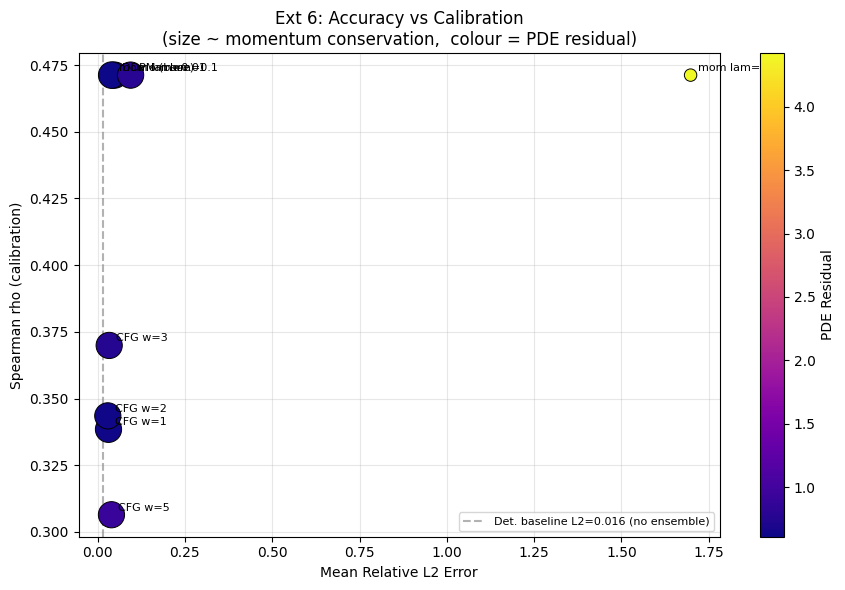

In [ ]:
pts6 = []

# base DDPM (from ext1 baseline + ext2 CFG rho at w=0)
pts6.append({'label': 'DDPM (base)',
             'l2': ext1_res[0.][0],
             'rho': cfg_rhos_e2.get(0., float('nan')),
             'mom': ext1_res[0.][1],
             'pde': ext1_res[0.][2]})

# CFG variants - L2/PDE from cell 7.4 (cfg_results), rho from ext2
for w in [1., 2., 3., 5.]:
    if w in cfg_results and w in cfg_rhos_e2:
        pts6.append({'label': f'CFG w={w:.0f}',
                     'l2': cfg_results[w]['l2_mean'],
                     'rho': cfg_rhos_e2[w],
                     'mom': ext1_res[0.][1],
                     'pde': cfg_results[w]['pde_res']})

# momentum penalty variants
for lam in [0.01, 0.1, 1.0]:
    if lam in ext1_res:
        pts6.append({'label': f'mom lam={lam}',
                     'l2': ext1_res[lam][0],
                     'rho': cfg_rhos_e2.get(0., float('nan')),
                     'mom': ext1_res[lam][1],
                     'pde': ext1_res[lam][2]})

l2_a  = np.array([p['l2']  for p in pts6])
rho_a = np.array([p['rho'] for p in pts6])
mom_a = np.array([p['mom'] for p in pts6])
pde_a = np.array([p['pde'] for p in pts6])

max_dr = np.nanmax(mom_a)

sizes6 = np.clip(300*(1 - mom_a/(max_dr+1e-6)) + 80, 50, 600)
norm6  = Normalize(vmin=np.nanmin(pde_a), vmax=np.nanmax(pde_a))
cmap6  = plt.cm.plasma

fig, ax = plt.subplots(figsize=(9, 6))
ax.scatter(l2_a, rho_a, s=sizes6, c=pde_a, cmap=cmap6, norm=norm6,
           edgecolors='black', lw=0.7, zorder=3)

for i, p in enumerate(pts6):
    if np.isfinite(p['rho']):
        ax.annotate(p['label'], (p['l2'], p['rho']),
                    textcoords='offset points', xytext=(5, 3), fontsize=8)

# deterministic baseline reference (no uncertainty axis)
ax.axvline(det_l2.mean(), color='gray', ls='--', alpha=0.6,
           label=f'Det. baseline L2={det_l2.mean():.3f} (no ensemble)')

plt.colorbar(ScalarMappable(norm=norm6, cmap=cmap6), ax=ax, label='PDE Residual')

ax.set_xlabel('Mean Relative L2 Error')
ax.set_ylabel('Spearman rho (calibration)')
ax.set_title('Ext 6: Accuracy vs Calibration\n'
             '(size ~ momentum conservation,  colour = PDE residual)')
ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

plt.tight_layout();
plt.show()


### Targeted Experiment A - $\eta$ Sweep for Spectral Ratio

DDIM stochasticity $\eta$ controls how much noise is injected at each reverse step.
We sweep $\eta \in \{0.3, 0.5, 0.7, 1.0\}$ at $S$=100 steps on 50 test samples and measure
both $L^2$ error and mean Fourier spectral ratio for wavenumbers $k$ > 10.

In [ ]:
# Experiment A: eta sweep - spectral ratio vs stochasticity
eta_values = [0.3, 0.5, 0.7, 1.0]

S_A = 100
N_A = 50

model.eval()
test_fields_A = test_data[:N_A].astype(np.float64)

conds_A = torch.from_numpy(test_data_norm[:N_A, 0:1, :]).to(device)

print(f"Experiment A: eta sweep at S={S_A}, N={N_A} test samples")
print(f"{'eta':>6s}  {'L^2 mean':>10s}  {'L^2 std':>10s}  {'Spec ratio (k>10)':>18s}")
print("-" * 52)

for eta_val in eta_values:
    gen_norm_list = []
    
    for start in range(0, N_A, 16):
        end = min(start + 16, N_A)
        
        g = ddim_sample(model, conds_A[start:end], num_steps=S_A, eta=eta_val)
        gen_norm_list.append(g.cpu().numpy())
    
    gen_norm = np.concatenate(gen_norm_list, axis=0)
    gen = (gen_norm * data_std + data_mean).astype(np.float64)

    # L2 errors
    l2s = []
    
    for i in range(N_A):
        err = np.sqrt(np.mean((gen[i] - test_fields_A[i])**2))
        ref = np.sqrt(np.mean(test_fields_A[i]**2))
        
        l2s.append(err / (ref + 1e-10))
    
    l2s = np.array(l2s)

    # Spectral ratio for k > 10
    ratios_high_k = []
    
    for i in range(N_A):
        _, ps_t = power_spectrum(test_fields_A[i])
        _, ps_g = power_spectrum(gen[i])
        ratio = ps_g / (ps_t + 1e-30)
        
        # k > 10 corresponds to indices where wavenumber > 10
        k_vals = np.fft.rfftfreq(NX, d=L / NX) * 2 * np.pi
        mask = k_vals > 10
        
        ratios_high_k.append(ratio[mask].mean())
    
    mean_spec = np.mean(ratios_high_k)

    print(f"{eta_val:6.1f}  {l2s.mean():10.4f}  {l2s.std():10.4f}  {mean_spec:18.3f}")

Experiment A: η sweep at S=100, N=50 test samples
     η     L² mean      L² std   Spec ratio (k>10)
----------------------------------------------------
   0.3      0.7203      0.2971    182418229352.993
   0.5      0.4408      0.1875     31622562428.252
   0.7      0.1591      0.0773      9529285058.379
   1.0      0.0468      0.0299        34150683.311


### Targeted Experiment B - Multi-Seed Main Model Evaluation

To confirm that the core results are stable across sampling noise,
we re-run the full 1000-step DDPM evaluation with 3 different random seeds
(different initial Gaussian noise $x_T$, same model weights) on the same 100 test samples.

In [ ]:
# Experiment B: Multi-seed evaluation (3 seeds)
N_B = min(100, N_TEST)
seeds_B = [42, 123, 7777]
n_ens_B = 10  # for calibration

model.eval()
test_true_B = test_data[:N_B].astype(np.float64)
conds_B = torch.from_numpy(test_data_norm[:N_B, 0:1, :]).to(device)

all_l2 = []
all_energy = []
all_rho = []

for seed in seeds_B:
    torch.manual_seed(seed)
    
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)

    # Generate samples
    gen_norm_list = []
    
    for start in range(0, N_B, 32):
        end = min(start + 32, N_B)
        g = ddpm_sample(model, conds_B[start:end], use_ema=True)
        
        gen_norm_list.append(g.cpu().numpy())
    
    gen_norm = np.concatenate(gen_norm_list, axis=0)
    gen = (gen_norm * data_std + data_mean).astype(np.float64)

    # L2 error
    l2s = []
    
    for i in range(N_B):
        err = np.sqrt(np.mean((gen[i] - test_true_B[i])**2))
        ref = np.sqrt(np.mean(test_true_B[i]**2))
        
        l2s.append(err / (ref + 1e-10))
    
    mean_l2 = np.mean(l2s)
    all_l2.append(mean_l2)

    # Energy error
    E_true = np.array([kinetic_energy(test_true_B[i]) for i in range(N_B)])
    E_gen  = np.array([kinetic_energy(gen[i]) for i in range(N_B)])
    rel_E = np.abs(E_gen.mean(0) - E_true.mean(0)) / (E_true.mean(0) + 1e-10)
    
    all_energy.append(rel_E.mean())

    # Calibration (Spearman rho) - use first 30 samples with 10-member ensembles
    n_cal = min(30, N_B)
    errs_flat, sprs_flat = [], []
    
    for i in range(n_cal):
        ci = conds_B[i:i+1].repeat(n_ens_B, 1, 1)
        ens_norm = ddpm_sample(model, ci, use_ema=True).cpu().numpy()
        ens = (ens_norm * data_std + data_mean).astype(np.float64)
        
        ens_mean = ens.mean(axis=0)
        ens_std  = ens.std(axis=0)
        abs_err  = np.abs(ens_mean - test_true_B[i])
        
        errs_flat.append(abs_err.ravel())
        sprs_flat.append(ens_std.ravel())
    
    rho_val, _ = spearmanr(np.concatenate(errs_flat), np.concatenate(sprs_flat))
    
    all_rho.append(rho_val)

    print(f"Seed {seed}: L2={mean_l2:.4f}, Energy err={rel_E.mean():.4f}, rho={rho_val:.3f}")

print(f"\nAcross 3 seeds:")
print(f"L^2 error:     {np.mean(all_l2):.4f} +/- {np.std(all_l2):.4f}")
print(f"Energy error: {np.mean(all_energy):.4f} +/- {np.std(all_energy):.4f}")
print(f"Spearman rho:   {np.mean(all_rho):.3f} +/- {np.std(all_rho):.3f}")


Seed 42: L2=0.0450, Energy err=0.0034, ρ=0.449


Seed 123: L2=0.0423, Energy err=0.0035, ρ=0.474


Seed 7777: L2=0.0391, Energy err=0.0055, ρ=0.470

Across 3 seeds:
  L² error:     0.0421 ± 0.0024
  Energy error: 0.0041 ± 0.0010
  Spearman ρ:   0.464 ± 0.011


### Targeted Experiment C - Mean Field Baseline

The simplest possible predictor: use the training-set mean field as the prediction
for every test sample. This gives a floor that contextualises the DDPM and regression numbers.

In [ ]:
# Experiment C: Mean field baseline (3 lines of real work)
mean_field = train_data.mean(axis=0).astype(np.float64)  # shape (NT, NX)
n_C = min(100, N_TEST)
true_C = test_data[:n_C].astype(np.float64)

l2_baseline = []

for i in range(n_C):
    err = np.sqrt(np.mean((mean_field - true_C[i])**2))
    ref = np.sqrt(np.mean(true_C[i]**2))
    
    l2_baseline.append(err / (ref + 1e-10))

l2_baseline = np.array(l2_baseline)

print(f"Mean field baseline L^2 error: {l2_baseline.mean():.3f} (median {np.median(l2_baseline):.3f})")

Mean field baseline L² error: 1.000 (median 1.000)


### Targeted Experiment D - Intermediate Viscosity $\nu$ = 0.03

We add one viscosity point between the hardest OOD case ($\nu$=0.01) and the
second-hardest ($\nu$=0.02) to check whether degradation from training viscosity is smooth.

In [ ]:
# Experiment D: nu = 0.03 intermediate viscosity
nu_new = 0.03
n_D = 50

model.eval()

test_D = generate_dataset(n_D, NX, L, nu_new, T_FINAL, NT,
                          N_MODES, IC_AMPLITUDE, seed=77777)
test_D_norm = (test_D - data_mean) / data_std
test_D_t = torch.from_numpy(test_D_norm).to(device)

conds_D = test_D_t[:, 0:1, :]
gen_D_norm = []

for start in range(0, n_D, 32):
    end = min(start + 32, n_D)
    g = ddpm_sample(model, conds_D[start:end], use_ema=True)
    
    gen_D_norm.append(g.cpu())

gen_D_norm = torch.cat(gen_D_norm, dim=0).numpy()
gen_D = (gen_D_norm * data_std + data_mean).astype(np.float64)
true_D = test_D.astype(np.float64)

# L2 error
l2s = []

for i in range(n_D):
    err = np.sqrt(np.mean((gen_D[i] - true_D[i])**2))
    ref = np.sqrt(np.mean(true_D[i]**2))
    
    l2s.append(err / (ref + 1e-10))

l2_D = np.array(l2s)

# Energy error
E_true = np.array([kinetic_energy(true_D[i]) for i in range(n_D)])
E_gen  = np.array([kinetic_energy(gen_D[i]) for i in range(n_D)])
rel_E = np.abs(E_gen.mean(0) - E_true.mean(0)) / (E_true.mean(0) + 1e-10)

# PDE residual
dx = L / NX
dt = T_FINAL / (NT - 1)
res_t = np.array([pde_residual(true_D[i], dx, dt, nu_new) for i in range(n_D)])
res_g = np.array([pde_residual(gen_D[i], dx, dt, nu_new) for i in range(n_D)])

print(f"ν = {nu_new}")
print(f"L^2 error:    {l2_D.mean():.3f} +/- {l2_D.std():.3f}")
print(f"Energy err:  {rel_E.mean():.3f}")
print(f"PDE residual (gen/true): {res_g.mean():.3f} / {res_t.mean():.3f}")


Generating: 100%|██████████| 50/50 [00:00<00:00, 265.63it/s]


  (rejected 112 unstable samples)


ν = 0.03
  L² error:    0.133 ± 0.076
  Energy err:  0.094
  PDE residual (gen/true): 0.325 / 1.675
